# 🧰 Fourier — MODO EXAMEN PANELES ANTITONTO

## Cómo usarlo
1. Ejecuta **UNA VEZ** la celda azul **CARGAR HERRAMIENTA**.
2. Busca el panel del tipo de ejercicio.
3. Cambia únicamente lo que está bajo **✏️ EDITA SOLO AQUÍ**.
4. Ejecuta ESA MISMA CELDA.
5. La respuesta sale justo debajo.

**NO uses Run All.** Cada panel es independiente.

### 🆕 Paneles exactos
- **Panel 1B**: igual al Panel 1, pero muestra la serie infinita exacta con sigma.
- **Panel 2B**: igual al Panel 2 para funciones por tramos, también con sigma.
- En esos paneles, `N` solo controla el espectro y la gráfica de comprobación.


# 🔵 CARGAR HERRAMIENTA

Ejecuta la siguiente celda **una sola vez** al abrir el notebook.  
No la edites.


In [4]:
# ============================================================
# ⚙️ INTERNA — NO EDITAR
# IMPORTS Y VARIABLES GENERALES
# ============================================================

import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
import re

from math import gcd, lcm
from IPython.display import display, Math

# Para poder escribir sin sp.
from sympy import (
    sin, cos, tan, pi, exp, sqrt, Abs, log,
    sinh, cosh, atan, atan2
)

# Parser que permite escribir 2t, 2π, ^, etc.
from sympy.parsing.sympy_parser import (
    parse_expr,
    standard_transformations,
    implicit_multiplication_application,
    convert_xor,
)

sp.init_printing()

t = sp.symbols('t', real=True)
n = sp.symbols('n', integer=True, positive=True)

# Alias en español
sen = sin


# ============================================================
# ⚙️ INTERNA — NO EDITAR
# CONVERTIDOR DE TEXTO A FÓRMULA MATEMÁTICA
# ============================================================

_TRANSFORMACIONES = standard_transformations + (
    implicit_multiplication_application,
    convert_xor,
)

_DICCIONARIO_MAT = {
    't': t,
    'n': n,
    'pi': pi,
    'sin': sin,
    'sen': sin,
    'cos': cos,
    'tan': tan,
    'exp': exp,
    'sqrt': sqrt,
    'Abs': Abs,
    'abs': Abs,
    'log': log,
    'e': sp.E,
    'E': sp.E,
    'I': sp.I,
}

def F(valor):
    '''
    Convierte algo escrito casi como en el examen a una expresión SymPy.

    Ejemplos:
        F("3 sin(2π·2·t)")
        F("t^2 + t")
        F("0,7 sin(10πt)")
    '''
    if isinstance(valor, sp.Basic):
        return valor

    if isinstance(valor, (int, float, np.integer, np.floating)):
        return sp.nsimplify(valor)

    s = str(valor).strip()

    s = s.replace('π', 'pi')
    s = s.replace('·', '*')
    s = s.replace('×', '*')
    s = s.replace('−', '-')
    s = s.replace('–', '-')
    s = s.replace('sen', 'sin')

    # 0,7 -> 0.7
    s = re.sub(r'(?<=\d),(?=\d)', '.', s)

    resultado = parse_expr(
        s,
        local_dict=_DICCIONARIO_MAT,
        transformations=_TRANSFORMACIONES,
        evaluate=True,
    )

    # Convierte decimales simples a fracciones exactas cuando puede:
    # 0.7 -> 7/10, 0.5 -> 1/2, etc.
    try:
        return sp.nsimplify(resultado)
    except Exception:
        return resultado

formula = F

def tramos(*partes, valor_fuera=0):
    '''
    Crea una función por partes sin tener que aprender Piecewise.

    Ejemplo:
        f = tramos(
            (0, -5, 0),
            (1,  0, 5)
        )
    '''
    piezas = []

    for parte in partes:
        if len(parte) != 3:
            raise ValueError(
                "Cada tramo debe tener: (función, inicio, fin)"
            )

        expr, a, b = parte
        expr = F(expr)
        a = F(a)
        b = F(b)

        piezas.append(
            (expr, (t >= a) & (t < b))
        )

    piezas.append((F(valor_fuera), True))
    return sp.Piecewise(*piezas)

def _V(valor):
    return F(valor)


def calcular_coeficientes(f, t_a, t_b, t=t, n=n, mostrar=True):
    '''
    Calcula dc (=a0/2), an, bn de la Serie Trigonométrica de Fourier de f(t)
    integrando sobre un periodo completo [t_a, t_b].

    f      : expresión simbólica de t (puede ser sp.Piecewise)
    t_a,t_b: límites de integración (deben abarcar un periodo T = t_b - t_a)
    '''
    T  = t_b - t_a
    w0 = 2*sp.pi/T

    dc = sp.simplify((sp.Rational(1,1)/T) * sp.integrate(f, (t, t_a, t_b)))
    an = sp.simplify((2/T) * sp.integrate(f*sp.cos(n*w0*t), (t, t_a, t_b)))
    bn = sp.simplify((2/T) * sp.integrate(f*sp.sin(n*w0*t), (t, t_a, t_b)))

    if mostrar:
        display(Math(r'T = ' + sp.latex(T) + r',\quad \omega_0 = ' + sp.latex(w0)))
        display(Math(r'\text{dc} = a_0/2 = ' + sp.latex(dc)))
        display(Math(r'a_n = ' + sp.latex(an)))
        display(Math(r'b_n = ' + sp.latex(bn)))

    return dc, an, bn, w0, T


def serie_expandida(dc, an, bn, w0, N=6, t=t, n=n, mostrar=True):
    '''Arma f(t) ≈ dc + sum_{i=1}^{N} [an(i)*cos(i*w0*t) + bn(i)*sin(i*w0*t)]'''
    expr = dc
    for i in range(1, N+1):
        ai = sp.simplify(an.subs(n, i)) if an != 0 else sp.Integer(0)
        bi = sp.simplify(bn.subs(n, i)) if bn != 0 else sp.Integer(0)
        if ai != 0:
            expr += ai * sp.cos(i*w0*t)
        if bi != 0:
            expr += bi * sp.sin(i*w0*t)

    if mostrar:
        display(Math(r'f(t) \approx ' + sp.latex(expr)))
    return expr


def tabla_armonicas(an, bn, N=9, n=n, imprimir=True, graficar=True):
    '''
    Calcula e imprime una tabla n, an, bn, Cn, %fundamental para n=0..N,
    y opcionalmente grafica el espectro de amplitud |Cn| vs n.
    '''
    filas = []
    for k in range(N+1):
        if k == 0:
            a_val, b_val = 0.0, 0.0
        else:
            try:
                a_val = float(sp.simplify(an.subs(n, k)))
            except Exception:
                a_val = float('nan')
            try:
                b_val = float(sp.simplify(bn.subs(n, k)))
            except Exception:
                b_val = float('nan')
        c_val = (a_val**2 + b_val**2)**0.5
        filas.append((k, a_val, b_val, c_val))

    c1 = filas[1][3] if (N >= 1 and filas[1][3] not in (0, float('nan'))) else 1.0

    if imprimir:
        print(f"{'n':>3} {'an':>10} {'bn':>10} {'Cn':>10} {'% fund.':>10}")
        print('-'*48)
        for k, a_val, b_val, c_val in filas:
            pct = 100*c_val/c1 if c1 else 0
            print(f"{k:3d} {a_val:10.4f} {b_val:10.4f} {c_val:10.4f} {pct:9.1f}%")

    if graficar:
        ns = [f[0] for f in filas]
        cs = [f[3] for f in filas]
        plt.figure(figsize=(6,3))
        plt.stem(ns, cs)
        plt.xlabel('n'); plt.ylabel('|Cn|')
        plt.title('Espectro de amplitud de armónicas')
        plt.grid(True, alpha=0.3)
        plt.show()

    return filas


def graficar_comparacion(f_expr, serie_expr, t_a, t_b, t=t, n_periodos=3, puntos=1500):
    '''
    f_expr    : f(t) simbólica (definida en un periodo [t_a, t_b])
    serie_expr: la serie truncada (salida de serie_expandida)
    '''
    T_f   = float(t_b - t_a)
    t_a_f = float(t_a)
    t_b_f = float(t_b)
    f_num = sp.lambdify(t, f_expr, 'numpy')
    s_num = sp.lambdify(t, serie_expr, 'numpy')

    tt = np.linspace(t_a_f - T_f*(n_periodos//2), t_b_f + T_f*(n_periodos//2), puntos)
    tt_mod = ((tt - t_a_f) % T_f) + t_a_f          # extensión periódica de f
    y_f = np.array([float(f_num(v)) for v in tt_mod], dtype=float)
    y_s = np.array([float(s_num(v)) for v in tt], dtype=float)

    plt.figure(figsize=(8,4))
    plt.plot(tt, y_f, 'k--', linewidth=1.6, label='f(t) original (periódica)')
    plt.plot(tt, y_s, 'b-',  linewidth=1.1, label='Serie truncada')
    plt.legend(); plt.grid(True, alpha=0.3)
    plt.xlabel('t'); plt.ylabel('f(t)')
    plt.title('f(t) vs. serie de Fourier truncada')
    plt.show()


def verificar_simetria(f, T, t=t):
    '''
    Evalúa si f(t), definida como expresión simbólica de un periodo T
    (por ejemplo centrada en 0 como [-T/2, T/2]), tiene simetría
    par, impar y/o de media onda, e imprime qué implica cada una.
    '''
    f_menos_t = sp.simplify(f.subs(t, -t))
    es_par    = sp.simplify(sp.expand(f_menos_t - f)) == 0
    es_impar  = sp.simplify(sp.expand(f_menos_t + f)) == 0

    f_medio = sp.simplify(f.subs(t, t + T/2))
    es_media_onda = sp.simplify(sp.expand(f_medio + f)) == 0

    print(f"Simetría par    (f(-t) = f(t))     : {es_par}")
    print(f"Simetría impar  (f(-t) = -f(t))    : {es_impar}")
    print(f"Media onda      (f(t+T/2) = -f(t)) : {es_media_onda}")

    if es_par:
        print(" -> bn = 0 para todo n. Serie solo con cosenos.")
    if es_impar:
        print(" -> a0/2 = 0 y an = 0 para todo n. Serie solo con senos.")
    if es_media_onda:
        print(" -> a0/2 = an = bn = 0 para n PAR. Solo armónicos impares.")
        if es_par:
            print("    (media onda + par) -> usa an = (8/T)*Integral_0^(T/4) f*cos(2*pi*n*t/T) dt, n impar")
        if es_impar:
            print("    (media onda + impar) -> usa bn = (8/T)*Integral_0^(T/4) f*sin(2*pi*n*t/T) dt, n impar")

    return es_par, es_impar, es_media_onda


def serie_medio_rango(f, L, tipo='coseno', t=t, n=n, mostrar=True):
    '''
    Calcula la serie de medio rango (extensión par->coseno, o impar->seno)
    de f(t) definida en [0, L].

    f    : expresión simbólica de t, definida en [0, L]
    L    : medio periodo (f está dada en [0, L])
    tipo : 'coseno' (extensión par) o 'seno' (extensión impar)
    '''
    tipo = tipo.lower()
    if tipo not in ('coseno', 'seno'):
        raise ValueError("tipo debe ser 'coseno' o 'seno'")

    if tipo == 'coseno':
        dc = sp.simplify((sp.Rational(1,1)/L) * sp.integrate(f, (t, 0, L)))
        an = sp.simplify((2/L) * sp.integrate(f*sp.cos(n*sp.pi*t/L), (t, 0, L)))
        bn = sp.Integer(0)
        if mostrar:
            display(Math(r'\text{Extensi\'on par (serie en cosenos), } T=2L:'))
            display(Math(r'a_0/2 = ' + sp.latex(dc)))
            display(Math(r'a_n = ' + sp.latex(an)))
            display(Math(r'b_n = 0'))
    else:
        dc = sp.Integer(0)
        an = sp.Integer(0)
        bn = sp.simplify((2/L) * sp.integrate(f*sp.sin(n*sp.pi*t/L), (t, 0, L)))
        if mostrar:
            display(Math(r'\text{Extensi\'on impar (serie en senos), } T=2L:'))
            display(Math(r'a_0/2 = 0'))
            display(Math(r'a_n = 0'))
            display(Math(r'b_n = ' + sp.latex(bn)))

    w0 = sp.pi / L   # equivale a 2*pi/T con T = 2L
    return dc, an, bn, w0


def serie_medio_rango_expandida(dc, an, bn, L, N=6, t=t, n=n, mostrar=True):
    '''Arma la serie expandida de medio rango con N términos (usa n*pi*t/L).'''
    expr = dc
    for i in range(1, N+1):
        ai = sp.simplify(an.subs(n, i)) if an != 0 else sp.Integer(0)
        bi = sp.simplify(bn.subs(n, i)) if bn != 0 else sp.Integer(0)
        if ai != 0:
            expr += ai * sp.cos(i*sp.pi*t/L)
        if bi != 0:
            expr += bi * sp.sin(i*sp.pi*t/L)
    if mostrar:
        display(Math(r'f(t) \approx ' + sp.latex(expr)))
    return expr


from math import gcd, lcm


# ============================================================
# SECCIÓN 10 — ANÁLISIS AUTOMÁTICO DE SENOides Y COSENOS
# ============================================================

def _mcd_racionales(valores):
    """
    Calcula el MCD exacto de una lista de números racionales.
    Se usa para encontrar la frecuencia fundamental.
    """

    vals = [sp.Rational(v) for v in valores]

    nums = [abs(int(v.p)) for v in vals]
    dens = [abs(int(v.q)) for v in vals]

    g_num = nums[0]

    for x in nums[1:]:
        g_num = gcd(g_num, x)

    l_den = dens[0]

    for x in dens[1:]:
        l_den = lcm(l_den, x)

    return sp.Rational(g_num, l_den)


# ============================================================
# Analizador principal
# ============================================================

def analizar_suma_senoides(terminos, mostrar=True, graficar=True):

    filas = []

    # --------------------------------------------------------
    # Analizar cada término
    # --------------------------------------------------------

    for term in terminos:

        A = sp.sympify(term.get('A', 0))
        phi = sp.sympify(term.get('phi', 0))
        tipo = term.get('tipo', 'sin').lower()

        # Componente constante DC
        if tipo == 'const':

            f = sp.Integer(0)
            w = sp.Integer(0)
            T_i = sp.oo

        # Si se proporcionó frecuencia lineal
        elif term.get('f') is not None:

            f = sp.simplify(
                sp.sympify(term['f'])
            )

            w = sp.simplify(
                2 * sp.pi * f
            )

            T_i = (
                sp.oo
                if f == 0
                else sp.simplify(1 / abs(f))
            )

        # Si se proporcionó frecuencia angular
        elif term.get('w') is not None:

            w = sp.simplify(
                sp.sympify(term['w'])
            )

            f = sp.simplify(
                w / (2 * sp.pi)
            )

            T_i = (
                sp.oo
                if w == 0
                else sp.simplify(2 * sp.pi / abs(w))
            )

        else:

            raise ValueError(
                "Cada término debe tener 'f', 'w', o tipo='const'."
            )

        # ----------------------------------------------------
        # Convertir amplitudes negativas a amplitud positiva
        # agregando pi a la fase
        # ----------------------------------------------------

        A_norm = A
        phi_norm = phi

        if (
            A.is_number
            and A.is_real
            and A.is_negative
        ):

            A_norm = -A

            phi_norm = sp.simplify(
                phi + sp.pi
            )

        filas.append({

            'A_original': A,

            'A': sp.simplify(A_norm),

            'f': sp.simplify(f),

            'w': sp.simplify(w),

            'T': T_i,

            'phi_original': phi,

            'phi': sp.simplify(phi_norm),

            'tipo': tipo
        })


    # ========================================================
    # CALCULAR FRECUENCIA FUNDAMENTAL
    # ========================================================

    freqs = [

        abs(
            sp.simplify(r['f'])
        )

        for r in filas

        if r['f'] != 0
    ]

    f0 = None
    T_total = None


    if freqs:

        ref = freqs[0]

        ratios = [

            sp.simplify(fi / ref)

            for fi in freqs
        ]


        if all(
            r.is_Rational
            for r in ratios
        ):

            g = _mcd_racionales(ratios)

            f0 = sp.simplify(
                ref * g
            )

            T_total = sp.simplify(
                1 / f0
            )


    # ========================================================
    # IDENTIFICAR ARMÓNICAS
    # ========================================================

    for r in filas:

        if r['f'] == 0:

            r['armonica'] = 0

        elif f0 is not None:

            r['armonica'] = sp.simplify(
                abs(r['f']) / f0
            )

        else:

            r['armonica'] = None


    # ========================================================
    # MOSTRAR TABLA
    # ========================================================

    if mostrar:

        print(
            f"{'#':>2} "
            f"{'tipo':>7} "
            f"{'Amp':>12} "
            f"{'f':>18} "
            f"{'w':>18} "
            f"{'T':>18} "
            f"{'fase':>14} "
            f"{'arm.':>8}"
        )

        print("-" * 112)


        for i, r in enumerate(filas, 1):

            print(
                f"{i:2d} "
                f"{r['tipo']:>7} "
                f"{str(r['A']):>12} "
                f"{str(r['f']):>18} "
                f"{str(r['w']):>18} "
                f"{str(r['T']):>18} "
                f"{str(r['phi']):>14} "
                f"{str(r['armonica']):>8}"
            )


        # ----------------------------------------------------
        # Datos de la señal completa
        # ----------------------------------------------------

        if f0 is not None:

            print("\nFrecuencia fundamental:")

            display(
                Math(
                    r'f_0='
                    + sp.latex(f0)
                )
            )

            print("Período fundamental:")

            display(
                Math(
                    r'T_0='
                    + sp.latex(T_total)
                )
            )

            print("Frecuencia angular fundamental:")

            display(
                Math(
                    r'\omega_0='
                    + sp.latex(
                        sp.simplify(
                            2 * sp.pi * f0
                        )
                    )
                )
            )

        elif freqs:

            print(
                "\nNo se pudo obtener una "
                "frecuencia fundamental exacta automáticamente."
            )


    # ========================================================
    # ESPECTRO DE AMPLITUD
    # ========================================================

    if graficar and freqs:

        xs = [

            float(
                sp.N(
                    abs(r['f'])
                )
            )

            for r in filas

            if r['f'] != 0
        ]

        ys = [

            float(
                sp.N(
                    abs(r['A'])
                )
            )

            for r in filas

            if r['f'] != 0
        ]


        plt.figure(
            figsize=(8, 4)
        )

        plt.stem(
            xs,
            ys
        )

        plt.xlabel(
            'Frecuencia f'
        )

        plt.ylabel(
            'Amplitud'
        )

        plt.title(
            'Espectro de amplitud'
        )

        plt.grid(
            True,
            alpha=0.3
        )

        plt.show()


    return filas, T_total


# ============================================================
# FUNCIÓN AUTOMÁTICA
# Tú solamente escribes f(t)
# ============================================================

def analizar_funcion_senoidal(
    expr,
    t=t,
    mostrar=True,
    graficar=True
):

    expr = sp.expand(expr)

    terminos = []


    # Separar la suma en términos individuales
    for termino in sp.Add.make_args(expr):

        # ----------------------------------------------------
        # COMPONENTE CONSTANTE (DC)
        # ----------------------------------------------------

        if not termino.has(t):

            terminos.append({

                'A': sp.simplify(termino),

                'tipo': 'const'
            })

            continue


        # ----------------------------------------------------
        # Buscar seno o coseno
        # ----------------------------------------------------

        trig_atoms = list(
            termino.atoms(
                sp.sin,
                sp.cos
            )
        )


        if len(trig_atoms) != 1:

            raise ValueError(
                "No pude interpretar automáticamente "
                f"el término:\n{termino}"
            )


        trig = trig_atoms[0]


        # ----------------------------------------------------
        # Detectar amplitud
        # ----------------------------------------------------

        A = sp.simplify(
            termino / trig
        )


        if A.has(t):

            raise ValueError(
                "La amplitud depende de t en:\n"
                f"{termino}"
            )


        # ----------------------------------------------------
        # Detectar seno o coseno
        # ----------------------------------------------------

        if trig.func == sp.sin:

            tipo = 'sin'

        else:

            tipo = 'cos'


        # ----------------------------------------------------
        # Argumento interno
        # Ej:
        # 2*pi*5*t + pi/8
        # ----------------------------------------------------

        argumento = sp.expand(
            trig.args[0]
        )


        # ----------------------------------------------------
        # FRECUENCIA ANGULAR
        #
        # derivada del argumento respecto de t
        # ----------------------------------------------------

        w = sp.simplify(
            sp.diff(
                argumento,
                t
            )
        )


        if w.has(t):

            raise ValueError(
                "El argumento no es lineal en t:\n"
                f"{argumento}"
            )


        # ----------------------------------------------------
        # FASE
        # ----------------------------------------------------

        phi = sp.simplify(
            argumento - w*t
        )


        # ----------------------------------------------------
        # Si omega aparece negativa
        # ----------------------------------------------------

        if (
            w.is_number
            and w.is_real
            and w.is_negative
        ):

            w = -w

            if tipo == 'sin':

                A = -A
                phi = -phi

            else:

                phi = -phi


        terminos.append({

            'A': sp.simplify(A),

            'w': sp.simplify(w),

            'phi': sp.simplify(phi),

            'tipo': tipo
        })


    # ========================================================
    # MOSTRAR FUNCIÓN INGRESADA
    # ========================================================

    if mostrar:

        print("Función ingresada:")

        display(
            Math(
                r'f(t)='
                + sp.latex(expr)
            )
        )

        print(
            "\nResultados:"
        )


    # ========================================================
    # ENVIAR AL ANALIZADOR
    # ========================================================

    filas, T_total = analizar_suma_senoides(

        terminos,

        mostrar=mostrar,

        graficar=graficar
    )


    return filas, T_total, terminos


def serie_compleja(f, t_a, t_b, N=10, t=t, mostrar=True, graficar=True):
    '''
    Calcula la serie compleja (exponencial) de Fourier de f(t) en [t_a, t_b].
    Devuelve c0, la expresión simbólica general de cn (en función de un
    símbolo entero m), y las listas numéricas ks, mags, fases para n=-N..N.
    '''
    m = sp.Symbol('m', integer=True)
    T  = t_b - t_a
    w0 = 2*sp.pi/T

    c0 = sp.simplify((1/T) * sp.integrate(f, (t, t_a, t_b)))
    cm = sp.simplify((1/T) * sp.integrate(f*sp.exp(-sp.I*m*w0*t), (t, t_a, t_b)))

    if mostrar:
        display(Math(r'c_0 = ' + sp.latex(c0)))
        display(Math(r'c_n = ' + sp.latex(cm) + r' \quad (n \neq 0)'))

    ks, mags, fases = [], [], []
    for k in range(-N, N+1):
        try:
            val = complex(c0) if k == 0 else complex(sp.simplify(cm.subs(m, k)).evalf())
        except Exception:
            val = complex('nan')
        ks.append(k)
        mags.append(abs(val))
        fases.append(0.0 if abs(val) < 1e-10 else float(np.angle(val)))

    if mostrar:
        print(f"\n{'n':>4} {'|cn|':>10} {'fase (rad)':>12}")
        print('-'*30)
        for k, mag, fa in zip(ks, mags, fases):
            print(f"{k:4d} {mag:10.4f} {fa:12.4f}")

    if graficar:
        plt.figure(figsize=(7,3))
        plt.stem(ks, mags)
        plt.xlabel('n'); plt.ylabel('|c_n|')
        plt.title('Espectro de amplitud (serie compleja)')
        plt.grid(True, alpha=0.3)
        plt.show()

        plt.figure(figsize=(7,3))
        plt.stem(ks, fases)
        plt.xlabel('n'); plt.ylabel('fase (rad)')
        plt.title('Espectro de fase (serie compleja)')
        plt.grid(True, alpha=0.3)
        plt.show()

    return c0, cm, ks, mags, fases


def graficar_senoides_y_suma(terminos, n_periodos=2, puntos=2500, T_manual=None):
    filas, T_total = analizar_suma_senoides(terminos, mostrar=False, graficar=False)

    if T_total is None:
        if T_manual is None:
            raise ValueError("No se pudo hallar T automáticamente. Pasá T_manual=...")
        T_total = sp.sympify(T_manual)

    T_num = float(sp.N(T_total))
    tt = np.linspace(0, n_periodos*T_num, puntos)

    componentes = []
    total = np.zeros_like(tt, dtype=float)

    for i, r in enumerate(filas, 1):
        A = float(sp.N(r['A_original']))
        phi = float(sp.N(r['phi_original']))
        w = float(sp.N(r['w']))

        if r['tipo'] == 'const':
            yy = np.full_like(tt, A, dtype=float)
            etiqueta = f"DC = {A:g}"
        elif r['tipo'] == 'cos':
            yy = A*np.cos(w*tt + phi)
            etiqueta = f"Componente {i}"
        elif r['tipo'] == 'sin':
            yy = A*np.sin(w*tt + phi)
            etiqueta = f"Componente {i}"
        else:
            raise ValueError("tipo debe ser 'sin', 'cos' o 'const'")

        componentes.append((etiqueta, yy))
        total += yy

    plt.figure(figsize=(10,4.5))
    plt.plot(tt, total, linewidth=2, label='Señal total')
    for etiqueta, yy in componentes:
        plt.plot(tt, yy, linewidth=1, alpha=0.8, label=etiqueta)

    plt.xlabel('t')
    plt.ylabel('Amplitud')
    plt.title(f'Señal y componentes — {n_periodos} períodos')
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

    return T_total


def serie_por_patron(dc, coef_n, w0=1, N=6, tipo='cos', patron='todos',
                      t=t, mostrar=True):
    '''
    coef_n: expresión de SymPy en función de n.
    patron:
      'todos'   -> n = 1,2,3,...
      'impares' -> n = 1,3,5,...
      lista     -> por ejemplo [1,3,6,10]
    N = cantidad de términos no constantes.
    '''
    if patron == 'todos':
        indices = list(range(1, N+1))
    elif patron == 'impares':
        indices = list(range(1, 2*N, 2))
    elif isinstance(patron, (list, tuple)):
        indices = list(patron)[:N]
    else:
        raise ValueError("patron debe ser 'todos', 'impares' o una lista.")

    expr = sp.sympify(dc)
    componentes = []

    for k in indices:
        ck = sp.simplify(sp.sympify(coef_n).subs(n, k))
        if tipo == 'cos':
            term = ck*sp.cos(k*w0*t)
        elif tipo == 'sin':
            term = ck*sp.sin(k*w0*t)
        else:
            raise ValueError("tipo debe ser 'cos' o 'sin'")

        expr += term
        componentes.append(sp.simplify(term))

    expr = sp.simplify(expr)

    if mostrar:
        display(Math(r'x_N(t)=' + sp.latex(expr)))

    return expr, indices, componentes

def graficar_serie_y_armonicas(dc, componentes, T, n_periodos=2, puntos=2200):
    T_num = float(sp.N(T))
    tt = np.linspace(0, n_periodos*T_num, puntos)

    total_expr = sp.sympify(dc) + sum(componentes, sp.Integer(0))
    total_fun = sp.lambdify(t, total_expr, 'numpy')
    yy_total = np.asarray(total_fun(tt), dtype=float)
    if yy_total.shape == ():
        yy_total = np.full_like(tt, float(yy_total))

    plt.figure(figsize=(10,4.5))
    plt.plot(tt, yy_total, linewidth=2, label='Serie truncada')

    for i, term in enumerate(componentes, 1):
        fun = sp.lambdify(t, term, 'numpy')
        yy = np.asarray(fun(tt), dtype=float)
        if yy.shape == ():
            yy = np.full_like(tt, float(yy))
        plt.plot(tt, yy, linewidth=1, alpha=0.8, label=f'Término {i}')

    plt.xlabel('t')
    plt.ylabel('x(t)')
    plt.title(f'Serie truncada y armónicas — {n_periodos} períodos')
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()


def combinar_seno_coseno(Acos, Bsin, w=1, t=t, mostrar=True):
    Acos = sp.sympify(Acos)
    Bsin = sp.sympify(Bsin)
    w = sp.sympify(w)

    R = sp.simplify(sp.sqrt(Acos**2 + Bsin**2))
    phi_cos = sp.atan2(Bsin, Acos)
    theta_sin = sp.atan2(Acos, Bsin)

    forma_cos = R*sp.cos(w*t - phi_cos)
    forma_sin = R*sp.sin(w*t + theta_sin)

    if mostrar:
        display(Math(r'R=' + sp.latex(R)))
        display(Math(r'\phi=' + sp.latex(phi_cos)))
        display(Math(r'\theta=' + sp.latex(theta_sin)))
        display(Math(sp.latex(Acos*sp.cos(w*t) + Bsin*sp.sin(w*t)) +
                     r'=' + sp.latex(forma_cos)))
        display(Math(sp.latex(Acos*sp.cos(w*t) + Bsin*sp.sin(w*t)) +
                     r'=' + sp.latex(forma_sin)))

    return R, phi_cos, theta_sin, forma_cos, forma_sin


def graficar_periodica(f_expr, t_a, t_b, n_periodos=3, puntos=2200, t=t):
    T = sp.simplify(t_b - t_a)
    T_num = float(sp.N(T))
    a_num = float(sp.N(t_a))

    inicio = a_num - T_num
    fin = inicio + n_periodos*T_num
    tt = np.linspace(inicio, fin, puntos)
    tt_mod = ((tt - a_num) % T_num) + a_num

    f_num = sp.lambdify(t, f_expr, 'numpy')
    try:
        yy = np.asarray(f_num(tt_mod), dtype=float)
        if yy.shape == ():
            yy = np.full_like(tt, float(yy))
    except Exception:
        yy = np.array([float(sp.N(f_expr.subs(t, v))) for v in tt_mod])

    plt.figure(figsize=(9,4))
    plt.plot(tt, yy)
    plt.xlabel('t')
    plt.ylabel('f(t)')
    plt.title(f'Extensión periódica — T = {sp.simplify(T)}')
    plt.grid(True, alpha=0.3)
    plt.show()

    return T


def clasificar_paridad(expr, t=t, mostrar=True):
    expr = sp.simplify(expr)
    fm = sp.simplify(expr.subs(t, -t))

    par = sp.simplify(fm - expr) == 0
    impar = sp.simplify(fm + expr) == 0

    if par:
        resultado = 'par'
    elif impar:
        resultado = 'impar'
    else:
        resultado = 'ninguna'

    if mostrar:
        print("Clasificación:", resultado)
        display(Math(r'f(-t)=' + sp.latex(fm)))

    return resultado

def integral_por_simetria(expr, L, t=t, mostrar=True):
    expr = sp.simplify(expr)
    L = sp.sympify(L)
    tipo = clasificar_paridad(expr, t=t, mostrar=False)

    if tipo == 'impar':
        resultado = sp.Integer(0)
        razon = r'\text{Integrando impar en }[-L,L]\Rightarrow I=0'
    elif tipo == 'par':
        resultado = sp.simplify(2*sp.integrate(expr, (t, 0, L)))
        razon = r'\text{Integrando par: }I=2\int_0^L f(t)\,dt'
    else:
        resultado = sp.simplify(sp.integrate(expr, (t, -L, L)))
        razon = r'\text{Sin paridad útil: se integra directamente}'

    if mostrar:
        display(Math(razon))
        display(Math(r'I=' + sp.latex(resultado)))

    return resultado, tipo


def verificar_ortogonalidad(m_val, n_val, w=1, tipo1='cos', tipo2='cos',
                            limites=None, graficar=True, t=t):
    m_val = sp.sympify(m_val)
    n_val = sp.sympify(n_val)
    w = sp.sympify(w)

    f1 = sp.cos(m_val*w*t) if tipo1 == 'cos' else sp.sin(m_val*w*t)
    f2 = sp.cos(n_val*w*t) if tipo2 == 'cos' else sp.sin(n_val*w*t)
    integrando = sp.simplify(f1*f2)

    if limites is None:
        a, b = -sp.pi/w, sp.pi/w
    else:
        a, b = limites

    I = sp.simplify(sp.integrate(integrando, (t, a, b)))

    display(Math(r'\int_{' + sp.latex(a) + '}^{' + sp.latex(b) + '}' +
                 sp.latex(integrando) + r'\,dt=' + sp.latex(I)))

    if graficar:
        aa = float(sp.N(a))
        bb = float(sp.N(b))
        tt = np.linspace(aa, bb, 1600)
        fun = sp.lambdify(t, integrando, 'numpy')
        yy = np.asarray(fun(tt), dtype=float)

        plt.figure(figsize=(8,3.5))
        plt.plot(tt, yy)
        plt.axhline(0, linewidth=0.8)
        plt.fill_between(tt, yy, 0, alpha=0.2)
        plt.xlabel('t')
        plt.ylabel('integrando')
        plt.title('Ortogonalidad: área neta')
        plt.grid(True, alpha=0.3)
        plt.show()

    return I


def serie_desde_espectro(dc, componentes, t=t, mostrar=True):
    '''
    componentes:
      {'A': amplitud_del_coseno, 'f': frecuencia_Hz, 'phi': fase_rad}
    o:
      {'A': ..., 'w': frecuencia_angular, 'phi': ...}
    '''
    expr = sp.sympify(dc)

    for c in componentes:
        A = sp.sympify(c['A'])
        phi = sp.sympify(c.get('phi', 0))
        if c.get('f') is not None:
            w = 2*sp.pi*sp.sympify(c['f'])
        else:
            w = sp.sympify(c['w'])
        expr += A*sp.cos(w*t + phi)

    expr = sp.simplify(expr)

    if mostrar:
        display(Math(r'f(t)=' + sp.latex(expr)))

    return expr


def fourier_pwm(A, m, T, N=6, t=t, n=n, mostrar=True):
    A, m, T = map(sp.sympify, (A, m, T))
    d = sp.simplify(m/T)
    w0 = sp.simplify(2*sp.pi/T)

    dc = sp.simplify(A*d)
    an = sp.simplify(2*A/(n*sp.pi) * sp.sin(n*sp.pi*d))
    bn = sp.Integer(0)

    if mostrar:
        display(Math(r'd=' + sp.latex(d)))
        display(Math(r'a_0/2=' + sp.latex(dc)))
        display(Math(r'a_n=' + sp.latex(an)))
        display(Math(r'b_n=0'))

    serie = serie_expandida(dc, an, bn, w0, N=N, mostrar=mostrar)
    return dc, an, bn, w0, serie


def diodo_taylor_fourier(a, k, Vm, w=1, orden=4, t=t, mostrar=True, graficar=False):
    a, k, Vm, w = map(sp.sympify, (a, k, Vm, w))
    x = sp.Symbol('x', real=True)

    i_taylor_x = sp.expand(
        a*sum((k*Vm*sp.cos(x))**r/sp.factorial(r) for r in range(1, orden+1))
    )

    dc = sp.simplify((1/(2*sp.pi))*sp.integrate(i_taylor_x, (x, -sp.pi, sp.pi)))

    coef = {}
    expr_fourier_x = dc

    for h in range(1, orden+1):
        ah = sp.simplify((1/sp.pi)*sp.integrate(
            i_taylor_x*sp.cos(h*x), (x, -sp.pi, sp.pi)
        ))
        coef[h] = ah
        if ah != 0:
            expr_fourier_x += ah*sp.cos(h*x)

    expr_fourier_t = sp.simplify(expr_fourier_x.subs(x, w*t))
    i_taylor_t = sp.simplify(i_taylor_x.subs(x, w*t))

    if mostrar:
        display(Math(r'i_{\mathrm{Taylor}}=' + sp.latex(i_taylor_t)))
        display(Math(r'i_{\mathrm{Fourier}}=' + sp.latex(expr_fourier_t)))
        display(Math(r'i_{DC}=' + sp.latex(dc)))
        print("Coeficientes de cos(n wt):")
        for h, val in coef.items():
            if val != 0:
                display(Math(r'i_' + str(h) + '=' + sp.latex(val)))

    if graficar:
        T0 = float(sp.N(2*sp.pi/w))
        tt = np.linspace(0, 2*T0, 1800)
        fun = sp.lambdify(t, expr_fourier_t, 'numpy')
        yy = np.asarray(fun(tt), dtype=float)

        plt.figure(figsize=(9,4))
        plt.plot(tt, yy)
        plt.xlabel('t')
        plt.ylabel('i(t)')
        plt.title(f'Aproximación del diodo — Taylor orden {orden}')
        plt.grid(True, alpha=0.3)
        plt.show()

    return i_taylor_t, expr_fourier_t, dc, coef


# ============================================================
# 🟢 MODO EXAMEN — COMANDOS FÁCILES
# ESTOS SÍ SON PARA USAR
#
# IMPORTANTE:
# - Ejecuta Run All UNA sola vez.
# - Cada resolver_... recibe TODOS sus inputs.
# - NINGUNO necesita variables de un ejercicio anterior.
# ============================================================

def ayuda_examen():
    print(r'''
==============================================================
             GUÍA RÁPIDA — QUÉ COMANDO USAR
==============================================================

1) SERIE TRIGONOMÉTRICA DE FOURIER
   resolver_fourier("t^2 + t", -pi, pi)

2) FOURIER DE FUNCIÓN POR TRAMOS
   resolver_fourier_tramos(
       [(0, -5, 0), (1, 0, 5)],
       desde=-5,
       hasta=5
   )

3) SERIE DE MEDIO RANGO
   resolver_medio_rango("2 - t", L=2, tipo="seno")

4) SUMA DE SENOIDES / FRECUENCIAS / ARMÓNICAS
   resolver_senoides(
       "3 sin(2π·2·t) - 4 sin(2π·4·t) + 0,7 sin(2π·5·t)"
   )

5) SERIE COMPLEJA
   resolver_compleja("e^t", -pi, pi, N=10)

6) SERIE YA DADA POR PATRÓN
   resolver_serie_dada(
       dc="pi/2",
       coef="4/(pi*n^2)",
       w0=1,
       patron="impares",
       tipo="cos",
       N=6
   )

7) A cos(wt) + B sin(wt) -> UNA SOLA SENOIDE
   resolver_combinar(Acos=0.5, Bsin=3.2, w=1)

8) SOLO GRAFICAR VARIOS PERÍODOS
   resolver_periodica("t^2", -1, 1, periodos=3)

9) PARIDAD / SIMETRÍA
   resolver_paridad("t^3*sin(t)")

10) INTEGRAL POR SIMETRÍA
    resolver_integral_simetria("t^3*sin(t)", L=pi)

11) ORTOGONALIDAD
    resolver_ortogonalidad(2, 3, w=1, tipo1="cos", tipo2="cos")

12) DESDE ESPECTRO DE AMPLITUD Y FASE
    resolver_desde_espectro(
        dc=5,
        componentes=[
            (3/2, 50, pi/8),
            (6, 300, pi/2)
        ]
    )

13) PULSO PWM
    resolver_pwm(A=1, m=2, T=5, N=6)

14) DIODO + TAYLOR
    resolver_diodo(a=0.1, k=6, Vm=0.2, w=1, orden=4)
''')


# ------------------------------------------------------------
# 1) FOURIER TRIGONOMÉTRICO COMPLETO
# ------------------------------------------------------------

def resolver_fourier(funcion, desde, hasta, N=6,
                     periodos=3, espectro=True,
                     comparar=True, simetria=True):
    '''
    Ejemplo:
        resolver_fourier("t^2 + t", -pi, pi)
    '''
    f = F(funcion)
    a = _V(desde)
    b = _V(hasta)

    print("="*68)
    print("SERIE TRIGONOMÉTRICA DE FOURIER")
    print("="*68)
    display(Math(r'f(t)=' + sp.latex(f)))
    display(Math(r'\text{Intervalo: }[' + sp.latex(a) + ',' + sp.latex(b) + ']'))

    dc, an, bn, w0, T = calcular_coeficientes(f, a, b, mostrar=True)

    print("\nSerie truncada:")
    serie = serie_expandida(dc, an, bn, w0, N=N, mostrar=True)

    if simetria:
        print("\nParidad/simetría:")
        try:
            tipo = clasificar_paridad(f, mostrar=False)
            print("Paridad detectada:", tipo)
            if sp.simplify(a + b) == 0:
                verificar_simetria(f, T)
        except Exception as e:
            print("No se pudo simplificar automáticamente la simetría:", e)

    tabla = None
    if espectro:
        print("\nTabla y espectro de armónicas:")
        tabla = tabla_armonicas(
            an, bn,
            N=max(N, 6),
            imprimir=True,
            graficar=True
        )

    if comparar:
        print("\nGráfica de la función y su aproximación:")
        graficar_comparacion(
            f, serie, a, b,
            n_periodos=periodos
        )

    return {
        'f': f, 'dc': dc, 'an': an, 'bn': bn,
        'w0': w0, 'T': T, 'serie': serie, 'tabla': tabla
    }


# ------------------------------------------------------------
# 2) FOURIER DE FUNCIÓN POR TRAMOS
# ------------------------------------------------------------

def resolver_fourier_tramos(partes, desde, hasta, N=6,
                            periodos=3, espectro=True,
                            comparar=True):
    '''
    Ejemplo:
        resolver_fourier_tramos(
            [(0,-5,0), (1,0,5)],
            desde=-5,
            hasta=5
        )

    Cada tramo es:
        (función, inicio, fin)
    '''
    f = tramos(*partes)

    print("Función por tramos detectada:")
    display(f)

    return resolver_fourier(
        f, desde, hasta,
        N=N,
        periodos=periodos,
        espectro=espectro,
        comparar=comparar,
        simetria=False
    )


# ------------------------------------------------------------
# 3) SERIE DE MEDIO RANGO
# ------------------------------------------------------------

def resolver_medio_rango(funcion, L, tipo="coseno",
                         N=6, periodos=3, graficar=True):
    '''
    Ejemplos:
        resolver_medio_rango("2-t", L=2, tipo="seno")
        resolver_medio_rango("3*t", L=pi, tipo="coseno")
    '''
    f = F(funcion)
    L = _V(L)
    tipo = str(tipo).lower().strip()

    print("="*68)
    print("SERIE DE MEDIO RANGO")
    print("="*68)
    display(Math(r'f(t)=' + sp.latex(f) + r',\quad 0\le t\le ' + sp.latex(L)))

    dc, an, bn, w0 = serie_medio_rango(
        f, L, tipo=tipo, mostrar=True
    )

    print("\nSerie truncada:")
    serie = serie_medio_rango_expandida(
        dc, an, bn,
        L=L, N=N,
        mostrar=True
    )

    if graficar:
        if tipo == "coseno":
            f_ext = sp.Piecewise(
                (f.subs(t, -t), (t >= -L) & (t < 0)),
                (f, (t >= 0) & (t < L)),
                (0, True)
            )
        elif tipo == "seno":
            f_ext = sp.Piecewise(
                (-f.subs(t, -t), (t >= -L) & (t < 0)),
                (f, (t >= 0) & (t < L)),
                (0, True)
            )
        else:
            raise ValueError('tipo debe ser "seno" o "coseno"')

        print("\nGráfica de la extensión y la serie:")
        graficar_comparacion(
            f_ext, serie, -L, L,
            n_periodos=periodos
        )

    return {
        'f': f, 'dc': dc, 'an': an, 'bn': bn,
        'w0': w0, 'T': 2*L, 'serie': serie
    }


# ------------------------------------------------------------
# 4) SUMA DE SENOIDES / COSENOS
#    Esta sola función reemplaza usar por separado 10 y 12.
# ------------------------------------------------------------

def resolver_senoides(funcion, periodos=2,
                      espectro=True, graficar=True):
    '''
    Ejemplo:
        resolver_senoides(
            "3 sin(2π·2·t) - 4 sin(2π·4·t) + 0,7 sin(2π·5·t)"
        )
    '''
    f = F(funcion)

    print("="*68)
    print("ANÁLISIS AUTOMÁTICO DE SENOIDES / COSENOS")
    print("="*68)

    filas, T_total, terminos = analizar_funcion_senoidal(
        f,
        mostrar=True,
        graficar=espectro
    )

    if graficar:
        print("\nGráfica de la señal total y sus componentes:")
        graficar_senoides_y_suma(
            terminos,
            n_periodos=periodos
        )

    return {
        'f': f,
        'filas': filas,
        'T': T_total,
        'terminos': terminos
    }


# ------------------------------------------------------------
# 5) SERIE COMPLEJA / EXPONENCIAL
# ------------------------------------------------------------

def resolver_compleja(funcion, desde, hasta, N=10,
                      graficar=True):
    '''
    Ejemplo:
        resolver_compleja("e^t", -pi, pi, N=10)
    '''
    f = F(funcion)
    a = _V(desde)
    b = _V(hasta)

    print("="*68)
    print("SERIE COMPLEJA DE FOURIER")
    print("="*68)
    display(Math(r'f(t)=' + sp.latex(f)))

    return serie_compleja(
        f, a, b,
        N=N,
        mostrar=True,
        graficar=graficar
    )


def resolver_compleja_tramos(partes, desde, hasta, N=10,
                             graficar=True):
    '''
    Ejemplo:
        resolver_compleja_tramos(
            [(1,0,2), (0,2,4)],
            desde=0,
            hasta=4,
            N=10
        )
    '''
    f = tramos(*partes)
    display(f)
    return resolver_compleja(
        f, desde, hasta,
        N=N,
        graficar=graficar
    )


# ------------------------------------------------------------
# 6) SERIE YA DADA POR PATRÓN
# ------------------------------------------------------------

def resolver_serie_dada(dc, coef, w0=1, N=6,
                        tipo="cos", patron="todos",
                        periodos=2, graficar=True):
    '''
    Ejemplo:
        resolver_serie_dada(
            dc="pi/2",
            coef="4/(pi*n^2)",
            w0=1,
            N=6,
            tipo="cos",
            patron="impares"
        )
    '''
    dc = F(dc)
    coef_n = F(coef)
    w0 = F(w0)

    print("="*68)
    print("SERIE DADA — TRUNCAMIENTO Y ARMÓNICAS")
    print("="*68)

    expr, indices, componentes = serie_por_patron(
        dc=dc,
        coef_n=coef_n,
        w0=w0,
        N=N,
        tipo=tipo,
        patron=patron,
        mostrar=True
    )

    T = sp.simplify(2*pi/abs(w0))
    display(Math(r'T=' + sp.latex(T)))

    if graficar:
        graficar_serie_y_armonicas(
            dc,
            componentes,
            T=T,
            n_periodos=periodos
        )

    return {
        'serie': expr,
        'indices': indices,
        'componentes': componentes,
        'T': T
    }


# ------------------------------------------------------------
# 7) A cos(wt) + B sin(wt) -> UNA SOLA SENOIDE
# ------------------------------------------------------------

def resolver_combinar(Acos, Bsin, w=1):
    Acos = sp.nsimplify(Acos)
    Bsin = sp.nsimplify(Bsin)
    w = sp.nsimplify(w)

    R = sp.sqrt(Acos**2 + Bsin**2)
    phi = sp.atan2(Acos, Bsin)

    R_num = sp.N(R, 6)
    phi_num = sp.N(phi, 6)

    respuesta = R_num * sp.sin(w*t + phi_num)

    print("RESPUESTA EN FORMA SENO")
    display(sp.Eq(sp.Symbol("R"), R_num))
    display(sp.Eq(sp.Symbol(r"\phi"), phi_num))
    display(sp.Eq(sp.Function("f")(t), respuesta))


# ------------------------------------------------------------
# 8) SOLO GRAFICAR UNA FUNCIÓN PERIÓDICA
# ------------------------------------------------------------

def resolver_periodica(funcion, desde, hasta, periodos=3):
    '''
    Ejemplo:
        resolver_periodica("t^2", -1, 1, periodos=3)
    '''
    f = F(funcion)
    a = F(desde)
    b = F(hasta)

    print("Función:")
    display(Math(r'f(t)=' + sp.latex(f)))

    T = graficar_periodica(
        f, a, b,
        n_periodos=periodos
    )

    display(Math(r'T=' + sp.latex(T)))
    return T


def resolver_periodica_tramos(partes, desde, hasta, periodos=3):
    '''
    Ejemplo:
        resolver_periodica_tramos(
            [("-t",-2,0), ("t",0,1)],
            desde=-2,
            hasta=1,
            periodos=3
        )
    '''
    f = tramos(*partes)
    display(f)
    return resolver_periodica(
        f, desde, hasta,
        periodos=periodos
    )


# ------------------------------------------------------------
# 9) PARIDAD / SIMETRÍA
# ------------------------------------------------------------

def resolver_paridad(funcion, T=None):
    '''
    Ejemplos:
        resolver_paridad("t^3*sin(t)")
        resolver_paridad("sin(t)", T=2*pi)
    '''
    f = F(funcion)

    print("="*68)
    print("PARIDAD / SIMETRÍA")
    print("="*68)
    display(Math(r'f(t)=' + sp.latex(f)))

    tipo = clasificar_paridad(f, mostrar=True)

    resultado_simetria = None
    if T is not None:
        T = F(T)
        print("\nSimetrías de Fourier:")
        resultado_simetria = verificar_simetria(f, T)

    return tipo, resultado_simetria


# ------------------------------------------------------------
# 10) INTEGRAL POR SIMETRÍA
# ------------------------------------------------------------

def resolver_integral_simetria(funcion, L):
    '''
    Calcula la integral de -L a L.

    Ejemplo:
        resolver_integral_simetria("t^3*sin(t)", L=pi)
    '''
    f = F(funcion)
    L = F(L)

    print("="*68)
    print("INTEGRAL USANDO SIMETRÍA")
    print("="*68)

    return integral_por_simetria(
        f, L,
        mostrar=True
    )


# ------------------------------------------------------------
# 11) ORTOGONALIDAD
# ------------------------------------------------------------

def resolver_ortogonalidad(m, n_arm, w=1,
                           tipo1="cos", tipo2="cos",
                           limites=None, graficar=True):
    '''
    Ejemplo:
        resolver_ortogonalidad(
            2, 3,
            w=1,
            tipo1="cos",
            tipo2="cos"
        )
    '''
    if limites is not None:
        limites = (
            F(limites[0]),
            F(limites[1])
        )

    return verificar_ortogonalidad(
        F(m),
        F(n_arm),
        w=F(w),
        tipo1=tipo1,
        tipo2=tipo2,
        limites=limites,
        graficar=graficar
    )


# ------------------------------------------------------------
# 12) RECONSTRUIR DESDE ESPECTRO DE AMPLITUD Y FASE
# ------------------------------------------------------------

def resolver_desde_espectro(dc, componentes,
                            periodos=2, graficar=True):
    '''
    Cada componente se escribe:
        (amplitud, frecuencia_Hz, fase)

    Ejemplo:
        resolver_desde_espectro(
            dc=5,
            componentes=[
                (3/2, 50, pi/8),
                (6, 300, pi/2)
            ]
        )
    '''
    dc = F(dc)

    comps_dict = []
    terminos = []

    if dc != 0:
        terminos.append({
            'A': dc,
            'tipo': 'const'
        })

    for A, freq, fase in componentes:
        A = F(A)
        freq = F(freq)
        fase = F(fase)

        comps_dict.append({
            'A': A,
            'f': freq,
            'phi': fase
        })

        terminos.append({
            'A': A,
            'f': freq,
            'phi': fase,
            'tipo': 'cos'
        })

    print("="*68)
    print("RECONSTRUCCIÓN DESDE ESPECTRO")
    print("="*68)

    expr = serie_desde_espectro(
        dc,
        comps_dict,
        mostrar=True
    )

    filas, T_total = analizar_suma_senoides(
        terminos,
        mostrar=True,
        graficar=False
    )

    if graficar and T_total is not None:
        graficar_senoides_y_suma(
            terminos,
            n_periodos=periodos
        )

    return {
        'f': expr,
        'filas': filas,
        'T': T_total,
        'terminos': terminos
    }


# ------------------------------------------------------------
# 13) PULSO PWM
# ------------------------------------------------------------

def resolver_pwm(A, m, T, N=6,
                 periodos=3, graficar=True):
    '''
    Ejemplo:
        resolver_pwm(A=1, m=2, T=5, N=6)
    '''
    A = F(A)
    m = F(m)
    T = F(T)

    print("="*68)
    print("PULSO PWM")
    print("="*68)

    dc, an, bn, w0, serie = fourier_pwm(
        A, m, T,
        N=N,
        mostrar=True
    )

    if graficar:
        f_pwm = sp.Piecewise(
            (A, (t >= -m/2) & (t < m/2)),
            (0, (t >= -T/2) & (t < T/2)),
            (0, True)
        )

        graficar_comparacion(
            f_pwm,
            serie,
            -T/2,
            T/2,
            n_periodos=periodos
        )

    return {
        'dc': dc, 'an': an, 'bn': bn,
        'w0': w0, 'T': T, 'serie': serie,
        'd': sp.simplify(m/T)
    }


# ------------------------------------------------------------
# 14) DIODO + TAYLOR
# ------------------------------------------------------------

def resolver_diodo(a, k, Vm, w=1,
                    orden=4, graficar=True):
    '''
    Ejemplo:
        resolver_diodo(
            a=0.1,
            k=6,
            Vm=0.2,
            w=1,
            orden=4
        )
    '''
    print("="*68)
    print("DIODO — TAYLOR + COMPONENTES DE FOURIER")
    print("="*68)

    return diodo_taylor_fourier(
        a=F(a),
        k=F(k),
        Vm=F(Vm),
        w=F(w),
        orden=int(orden),
        mostrar=True,
        graficar=graficar
    )



# ============================================================
# CORRECCIÓN v2 — CONSERVAR EL ORDEN ORIGINAL DE LOS TÉRMINOS
# ============================================================

def _separar_terminos_en_orden(texto):
    """
    Separa una suma/resta en términos SIN cambiar el orden escrito por el usuario.
    Respeta signos dentro de paréntesis.

    Ejemplo:
      3 sin(...) - 4 sin(...) + 0,7 sin(...)
    devuelve:
      ['3 sin(...)', '- 4 sin(...)', '+ 0,7 sin(...)']
    """
    s = str(texto).strip()
    s = s.replace('−', '-').replace('–', '-')

    terminos = []
    inicio = 0
    nivel = 0

    for i, ch in enumerate(s):
        if ch == '(':
            nivel += 1
        elif ch == ')':
            nivel -= 1
        elif nivel == 0 and i > 0 and ch in '+-':
            # Evitar separar signos que pertenecen a notación científica, por seguridad.
            prev = s[i-1]
            if prev not in 'eE':
                pedazo = s[inicio:i].strip()
                if pedazo:
                    terminos.append(pedazo)
                inicio = i

    ultimo = s[inicio:].strip()
    if ultimo:
        terminos.append(ultimo)

    return terminos


def _analizar_un_termino_senoidal(termino_expr, expresion_original=None):
    """
    Convierte UN término (constante, seno o coseno) al formato interno
    sin alterar su posición respecto a los demás.
    """
    termino = sp.expand(termino_expr)

    # Componente DC
    if not termino.has(t):
        return {
            'A': sp.simplify(termino),
            'tipo': 'const',
            'expresion': expresion_original if expresion_original is not None else str(termino)
        }

    trig_atoms = list(termino.atoms(sp.sin, sp.cos))

    if len(trig_atoms) != 1:
        raise ValueError(
            f"No pude interpretar automáticamente este término: {termino}"
        )

    trig = trig_atoms[0]
    A = sp.simplify(termino / trig)

    if A.has(t):
        raise ValueError(
            f"La amplitud depende de t en el término: {termino}"
        )

    tipo = 'sin' if trig.func == sp.sin else 'cos'
    argumento = sp.expand(trig.args[0])
    w = sp.simplify(sp.diff(argumento, t))

    if w.has(t):
        raise ValueError(
            f"El argumento no es lineal en t: {argumento}"
        )

    phi = sp.simplify(argumento - w*t)

    # Normalizar omega positiva.
    if w.is_number and w.is_real and w.is_negative:
        w = -w
        if tipo == 'sin':
            A = -A
            phi = -phi
        else:
            phi = -phi

    return {
        'A': sp.simplify(A),
        'w': sp.simplify(w),
        'phi': sp.simplify(phi),
        'tipo': tipo,
        'expresion': expresion_original if expresion_original is not None else str(termino)
    }


def analizar_funcion_senoidal_ordenada(funcion, mostrar=True, graficar=True):
    """
    Analiza una suma de senos/cosenos CONSERVANDO EL ORDEN ORIGINAL.

    Si `funcion` es texto, T1, T2, T3... corresponden EXACTAMENTE al
    primer, segundo, tercer... término tal como fueron escritos.
    """
    if isinstance(funcion, str):
        textos = _separar_terminos_en_orden(funcion)
        terminos = []

        for texto in textos:
            expr_term = F(texto)
            terminos.append(
                _analizar_un_termino_senoidal(
                    expr_term,
                    expresion_original=texto.strip()
                )
            )

        expr_total = F(funcion)

    else:
        # Si no es texto, SymPy puede reordenar; se conserva el orden que
        # SymPy entregue, pero se avisa.
        expr_total = sp.expand(funcion)
        terminos = []
        for termino in sp.Add.make_args(expr_total):
            terminos.append(
                _analizar_un_termino_senoidal(
                    termino,
                    expresion_original=str(termino)
                )
            )

    if mostrar:
        print("Función ingresada:")
        display(Math(r'f(t)=' + sp.latex(expr_total)))
        print("\nIMPORTANTE: T1, T2, T3... siguen el orden en que escribiste los términos.")
        print("\nCorrespondencia:")
        for i, term in enumerate(terminos, 1):
            print(f"  T{i}  ->  {term['expresion']}")
        print("\nResultados:")

    filas, T_total = analizar_suma_senoides_v2(
        terminos,
        mostrar=mostrar,
        graficar=graficar
    )

    return filas, T_total, terminos


def analizar_suma_senoides_v2(terminos, mostrar=True, graficar=True):
    """
    Igual que analizar_suma_senoides, pero:
    - conserva el orden recibido;
    - etiqueta cada fila como T1, T2, T3...;
    - muestra la expresión original para evitar confusiones.
    """
    filas = []

    for idx, term in enumerate(terminos, 1):
        A = sp.sympify(term.get('A', 0))
        phi = sp.sympify(term.get('phi', 0))
        tipo = term.get('tipo', 'sin').lower()
        expresion = term.get('expresion', f'Término {idx}')

        if tipo == 'const':
            f = sp.Integer(0)
            w = sp.Integer(0)
            T_i = sp.oo

        elif term.get('f') is not None:
            f = sp.simplify(sp.sympify(term['f']))
            w = sp.simplify(2*sp.pi*f)
            T_i = sp.oo if f == 0 else sp.simplify(1/abs(f))

        elif term.get('w') is not None:
            w = sp.simplify(sp.sympify(term['w']))
            f = sp.simplify(w/(2*sp.pi))
            T_i = sp.oo if w == 0 else sp.simplify(2*sp.pi/abs(w))

        else:
            raise ValueError("Cada término debe tener 'f', 'w', o tipo='const'.")

        A_norm = A
        phi_norm = phi

        if A.is_number and A.is_real and A.is_negative:
            A_norm = -A
            phi_norm = sp.simplify(phi + sp.pi)

        filas.append({
            'numero': idx,
            'nombre': f'T{idx}',
            'expresion': expresion,
            'A_original': A,
            'A': sp.simplify(A_norm),
            'f': sp.simplify(f),
            'w': sp.simplify(w),
            'T': T_i,
            'phi_original': phi,
            'phi': sp.simplify(phi_norm),
            'tipo': tipo
        })

    # Fundamental
    freqs = [abs(sp.simplify(r['f'])) for r in filas if r['f'] != 0]
    f0 = None
    T_total = None

    if freqs:
        ref = freqs[0]
        ratios = [sp.simplify(fi/ref) for fi in freqs]

        if all(r.is_Rational for r in ratios):
            g = _mcd_racionales(ratios)
            f0 = sp.simplify(ref*g)
            T_total = sp.simplify(1/f0)

    for r in filas:
        if r['f'] == 0:
            r['armonica'] = 0
        elif f0 is not None:
            r['armonica'] = sp.simplify(abs(r['f'])/f0)
        else:
            r['armonica'] = None

    if mostrar:
        print(
            f"{'Term':>5} {'tipo':>7} {'Amp':>10} {'f':>14} "
            f"{'w':>16} {'T':>14} {'fase':>12} {'arm.':>7}"
        )
        print('-'*94)

        for r in filas:
            print(
                f"{r['nombre']:>5} {r['tipo']:>7} {str(r['A']):>10} "
                f"{str(r['f']):>14} {str(r['w']):>16} "
                f"{str(r['T']):>14} {str(r['phi']):>12} "
                f"{str(r['armonica']):>7}"
            )

        print("\nQué significa cada fila:")
        for r in filas:
            print(f"  {r['nombre']} = {r['expresion']}")

        if f0 is not None:
            print("\nFrecuencia fundamental:")
            display(Math(r'f_0=' + sp.latex(f0)))

            print("Período fundamental:")
            display(Math(r'T_0=' + sp.latex(T_total)))

            print("Frecuencia angular fundamental:")
            display(Math(
                r'\omega_0=' +
                sp.latex(sp.simplify(2*sp.pi*f0))
            ))

        elif freqs:
            print("\nNo se pudo obtener una frecuencia fundamental exacta automáticamente.")

    if graficar and freqs:
        xs = [float(sp.N(abs(r['f']))) for r in filas if r['f'] != 0]
        ys = [float(sp.N(abs(r['A']))) for r in filas if r['f'] != 0]

        plt.figure(figsize=(8,4))
        plt.stem(xs, ys)
        plt.xlabel('Frecuencia f')
        plt.ylabel('Amplitud')
        plt.title('Espectro de amplitud')
        plt.grid(True, alpha=0.3)
        plt.show()

    return filas, T_total


def graficar_senoides_y_suma_v2(terminos, n_periodos=2, puntos=2500, T_manual=None):
    """
    Gráfica corregida:
    las etiquetas T1, T2, T3 siguen exactamente el orden original.
    """
    filas, T_total = analizar_suma_senoides_v2(
        terminos,
        mostrar=False,
        graficar=False
    )

    if T_total is None:
        if T_manual is None:
            raise ValueError("No se pudo hallar T automáticamente. Pasá T_manual=...")
        T_total = sp.sympify(T_manual)

    T_num = float(sp.N(T_total))
    tt = np.linspace(0, n_periodos*T_num, puntos)

    componentes = []
    total = np.zeros_like(tt, dtype=float)

    for r in filas:
        A = float(sp.N(r['A_original']))
        phi = float(sp.N(r['phi_original']))
        w = float(sp.N(r['w']))

        if r['tipo'] == 'const':
            yy = np.full_like(tt, A, dtype=float)

        elif r['tipo'] == 'cos':
            yy = A*np.cos(w*tt + phi)

        elif r['tipo'] == 'sin':
            yy = A*np.sin(w*tt + phi)

        else:
            raise ValueError("tipo debe ser 'sin', 'cos' o 'const'")

        etiqueta = f"{r['nombre']}: {r['expresion']}"
        componentes.append((etiqueta, yy))
        total += yy

    plt.figure(figsize=(11,4.8))
    plt.plot(tt, total, linewidth=2, label='Señal total')

    for etiqueta, yy in componentes:
        plt.plot(tt, yy, linewidth=1, alpha=0.85, label=etiqueta)

    plt.xlabel('t')
    plt.ylabel('Amplitud')
    plt.title(f'Señal y componentes — {n_periodos} períodos')
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

    return T_total


# Sobrescribir el comando fácil del PANEL 4 con la versión corregida.
def resolver_senoides(funcion, periodos=2, espectro=True, graficar=True):
    """
    Analiza la función manteniendo EXACTAMENTE el orden escrito:
    T1 = primer término, T2 = segundo término, etc.
    """
    print("="*68)
    print("ANÁLISIS AUTOMÁTICO DE SENOIDES / COSENOS")
    print("="*68)

    filas, T_total, terminos = analizar_funcion_senoidal_ordenada(
        funcion,
        mostrar=True,
        graficar=espectro
    )

    if graficar:
        print("\nGráfica de la señal total y sus componentes:")
        graficar_senoides_y_suma_v2(
            terminos,
            n_periodos=periodos
        )

    return {
        'f': F(funcion) if isinstance(funcion, str) else funcion,
        'filas': filas,
        'T': T_total,
        'terminos': terminos
    }


print("✅ HERRAMIENTA CARGADA — usa cualquier panel de abajo.")


# ============================================================
# ⚙️ INTERNA — SERIES EXACTAS (SIN MOSTRAR TRUNCAMIENTO)
# ============================================================

def _mostrar_serie_fourier_exacta(dc, an, bn, w0):
    """
    Muestra la representación trigonométrica exacta:
    dc + Sum(an*cos(n*w0*t) + bn*sin(n*w0*t), n=1..infinito)
    """
    termino = an*sp.cos(n*w0*t) + bn*sp.sin(n*w0*t)
    termino = sp.expand_mul(termino)

    if sp.simplify(dc) == 0:
        latex_serie = (
            r'\sum_{n=1}^{\infty}\left('
            + sp.latex(termino)
            + r'\right)'
        )
    elif sp.simplify(termino) == 0:
        latex_serie = sp.latex(dc)
    else:
        latex_serie = (
            sp.latex(dc)
            + r' + \sum_{n=1}^{\infty}\left('
            + sp.latex(termino)
            + r'\right)'
        )

    print("\nSERIE EXACTA / FORMA GENERAL:")
    display(Math(r'\boxed{f(t)=' + latex_serie + r'}'))

    return dc + sp.Sum(termino, (n, 1, sp.oo))


def resolver_fourier_exacta(funcion, desde, hasta, N=6,
                            periodos=3, espectro=True,
                            comparar=True, simetria=True):
    """
    Igual que PANEL 1, pero la respuesta principal se muestra
    como serie infinita exacta con sigma, NO como serie truncada.

    N solo se usa para:
      - tabla/espectro de las primeras armónicas
      - gráfica aproximada, si comparar=True
    """
    f = F(funcion)
    a = _V(desde)
    b = _V(hasta)

    print("="*68)
    print("SERIE TRIGONOMÉTRICA DE FOURIER — EXACTA")
    print("="*68)
    display(Math(r'f(t)=' + sp.latex(f)))
    display(Math(r'\text{Intervalo: }[' + sp.latex(a) + ',' + sp.latex(b) + ']'))

    dc, an, bn, w0, T = calcular_coeficientes(f, a, b, mostrar=True)

    serie_exacta = _mostrar_serie_fourier_exacta(dc, an, bn, w0)

    if simetria:
        print("\nParidad/simetría:")
        try:
            tipo = clasificar_paridad(f, mostrar=False)
            print("Paridad detectada:", tipo)
            if sp.simplify(a + b) == 0:
                verificar_simetria(f, T)
        except Exception as e:
            print("No se pudo simplificar automáticamente la simetría:", e)

    tabla = None
    if espectro:
        print("\nTabla y espectro de las primeras armónicas:")
        tabla = tabla_armonicas(
            an, bn,
            N=max(N, 6),
            imprimir=True,
            graficar=True
        )

    serie_aprox = None
    if comparar:
        # Solo para poder graficar. NO se muestra como respuesta.
        serie_aprox = serie_expandida(
            dc, an, bn, w0,
            N=N,
            mostrar=False
        )
        print(
            "\nGráfica de comprobación "
            f"(usa {N} armónicas solo para visualizar):"
        )
        graficar_comparacion(
            f, serie_aprox, a, b,
            n_periodos=periodos
        )

    return {
        'f': f, 'dc': dc, 'an': an, 'bn': bn,
        'w0': w0, 'T': T,
        'serie_exacta': serie_exacta,
        'serie_aprox_grafica': serie_aprox,
        'tabla': tabla
    }


def resolver_fourier_tramos_exacta(partes, desde, hasta, N=6,
                                   periodos=3, espectro=True,
                                   comparar=True):
    """
    Igual que PANEL 2, pero muestra la serie infinita exacta
    con sigma en lugar de la serie truncada.
    """
    f = tramos(*partes)

    print("Función por tramos detectada:")
    display(f)

    return resolver_fourier_exacta(
        f, desde, hasta,
        N=N,
        periodos=periodos,
        espectro=espectro,
        comparar=comparar,
        simetria=False
    )



✅ HERRAMIENTA CARGADA — usa cualquier panel de abajo.


## PANEL 1 — Serie trigonométrica de Fourier

Cambia solo los datos marcados y ejecuta la celda de abajo.


SERIE TRIGONOMÉTRICA DE FOURIER


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>


Serie truncada:


<IPython.core.display.Math object>


Paridad/simetría:
Paridad detectada: ninguna
Simetría par    (f(-t) = f(t))     : False
Simetría impar  (f(-t) = -f(t))    : False
Media onda      (f(t+T/2) = -f(t)) : False

Tabla y espectro de armónicas:
  n         an         bn         Cn    % fund.
------------------------------------------------
  0     0.0000     0.0000     0.0000       0.0%
  1    -4.0000     2.0000     4.4721     100.0%
  2     1.0000    -1.0000     1.4142      31.6%
  3    -0.4444     0.6667     0.8012      17.9%
  4     0.2500    -0.5000     0.5590      12.5%
  5    -0.1600     0.4000     0.4308       9.6%
  6     0.1111    -0.3333     0.3514       7.9%


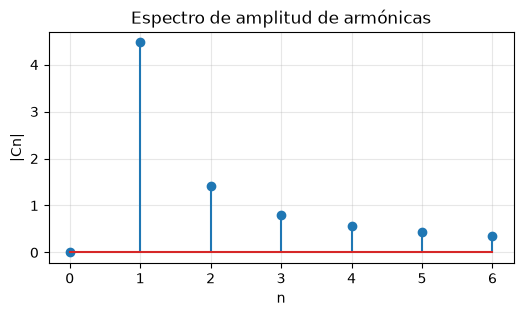


Gráfica de la función y su aproximación:


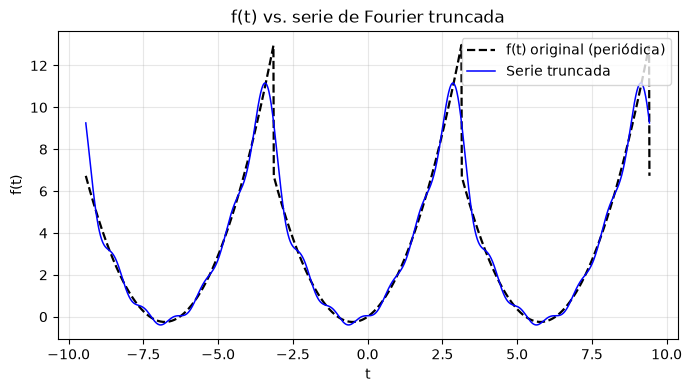

{'f': t**2 + t,
 'dc': pi**2/3,
 'an': 4*(-1)**n/n**2,
 'bn': -2*(-1)**n/n,
 'w0': 1,
 'T': 2*pi,
 'serie': 2*sin(t) - sin(2*t) + 2*sin(3*t)/3 - sin(4*t)/2 + 2*sin(5*t)/5 - sin(6*t)/3 - 4*cos(t) + cos(2*t) - 4*cos(3*t)/9 + cos(4*t)/4 - 4*cos(5*t)/25 + cos(6*t)/9 + pi**2/3,
 'tabla': [(0, 0.0, 0.0, 0.0),
  (1, -4.0, 2.0, 4.47213595499958),
  (2, 1.0, -1.0, 1.4142135623730951),
  (3, -0.4444444444444444, 0.6666666666666666, 0.8012336167697753),
  (4, 0.25, -0.5, 0.5590169943749475),
  (5, -0.16, 0.4, 0.4308131845707604),
  (6, 0.1111111111111111, -0.3333333333333333, 0.35136418446315326)]}

In [10]:
# ✏️ EDITA SOLO AQUÍ
FUNCION = "t^2 + t"
DESDE = -pi
HASTA = pi
N = 6
# 🛑 NO TOCAR DESDE AQUÍ
resolver_fourier(FUNCION, DESDE, HASTA, N=N)


## PANEL 2 — Fourier de función por partes

Cambia solo los datos marcados y ejecuta la celda de abajo.


Función por tramos detectada:


⎧  0    for t ≥ -2 ∧ t < -1
⎪                          
⎪t + 2  for t ≥ -1 ∧ t < 0 
⎪                          
⎪2 - t   for t ≥ 0 ∧ t < 1 
⎪                          
⎨  0     for t ≥ 1 ∧ t < 3 
⎪                          
⎪2 - t   for t ≥ 3 ∧ t < 4 
⎪                          
⎪t - 6   for t ≥ 4 ∧ t < 5 
⎪                          
⎩  0         otherwise     

SERIE TRIGONOMÉTRICA DE FOURIER


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>


Serie truncada:


<IPython.core.display.Math object>


Tabla y espectro de armónicas:
  n         an         bn         Cn    % fund.
------------------------------------------------
  0     0.0000     0.0000     0.0000       0.0%
  1     1.3751     0.0000     1.3751     100.0%
  2     0.0000     0.0000     0.0000       0.0%
  3     0.6076     0.0000     0.6076      44.2%
  4     0.0000     0.0000     0.0000       0.0%
  5    -0.0694     0.0000     0.0694       5.0%
  6     0.0000     0.0000     0.0000       0.0%


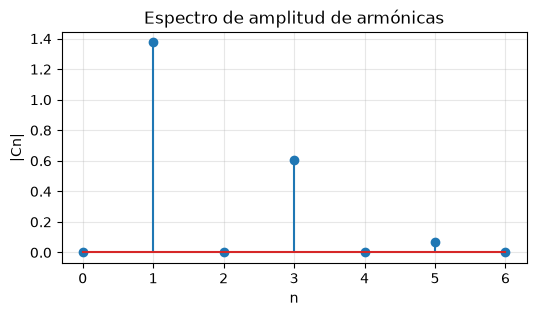


Gráfica de la función y su aproximación:


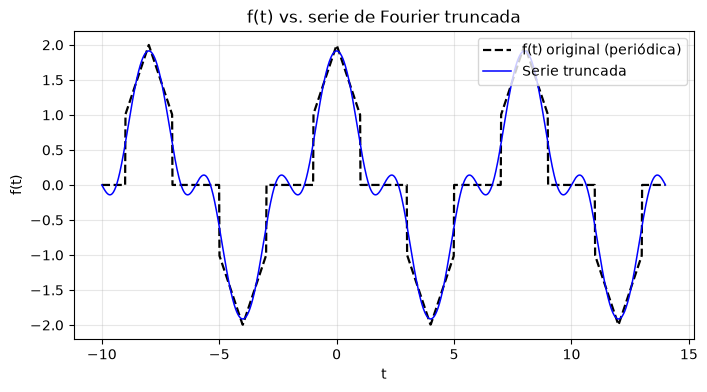

{'f': Piecewise((0, (t >= -2) & (t < -1)), (t + 2, (t >= -1) & (t < 0)), (2 - t, (t >= 0) & (t < 1)), (0, (t >= 1) & (t < 3)), (2 - t, (t >= 3) & (t < 4)), (t - 6, (t >= 4) & (t < 5)), (0, True)),
 'dc': 0,
 'an': (-8*(-1)**n + pi*n*(2*sin(pi*n/4) + sin(3*pi*n/4) - sin(5*pi*n/4)) - 8*cos(pi*n/4) + 4*cos(3*pi*n/4) + 4*cos(5*pi*n/4) + 8)/(pi**2*n**2),
 'bn': (pi*n*(-cos(3*pi*n/4) + cos(5*pi*n/4)) + 4*sin(3*pi*n/4) + 4*sin(5*pi*n/4))/(pi**2*n**2),
 'w0': pi/4,
 'T': 8,
 'serie': 2*(-4*sqrt(2) + sqrt(2)*pi + 8)*cos(pi*t/4)/pi**2 + 2*(4*sqrt(2) + 8 + 3*sqrt(2)*pi)*cos(3*pi*t/4)/(9*pi**2) + 2*(-5*sqrt(2)*pi + 4*sqrt(2) + 8)*cos(5*pi*t/4)/(25*pi**2),
 'tabla': [(0, 0.0, 0.0, 0.0),
  (1, 1.375136917932998, 0.0, 1.375136917932998),
  (2, 0.0, 0.0, 0.0),
  (3, 0.6076006914722484, 0.0, 0.6076006914722484),
  (4, 0.0, 0.0, 0.0),
  (5, -0.06936497224026454, 0.0, 0.06936497224026454),
  (6, 0.0, 0.0, 0.0)]}

In [10]:
# ✏️ EDITA SOLO AQUÍ
TRAMOS = [
    (0, -2, -1),
    ("t+2",  -1, 0),
    ("-t+2",  0, 1),
    (0,  1, 3),
    ("-t+2",  3, 4),
    ("t-6",  4, 5),
    (0,  5, 6),
]
DESDE = -2
HASTA = 6
N = 6
# 🛑 NO TOCAR DESDE AQUÍ
resolver_fourier_tramos(TRAMOS, desde=DESDE, hasta=HASTA, N=N)


## PANEL 1B — Serie trigonométrica de Fourier EXACTA

Hace lo mismo que el **Panel 1**, pero la respuesta principal sale con $\sum_{n=1}^{\infty}$ en vez de mostrar una serie truncada.

**`N` solo se usa para el espectro y la gráfica de comprobación; no cambia la serie exacta.**


SERIE TRIGONOMÉTRICA DE FOURIER — EXACTA


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>


SERIE EXACTA / FORMA GENERAL:


<IPython.core.display.Math object>


Paridad/simetría:
Paridad detectada: ninguna

Tabla y espectro de las primeras armónicas:
  n         an         bn         Cn    % fund.
------------------------------------------------
  0     0.0000     0.0000     0.0000       0.0%
  1     0.6142     0.8424     1.0425     100.0%
  2     0.0000     0.0000     0.0000       0.0%
  3     0.0000     0.0000     0.0000       0.0%
  4     0.0000     0.0000     0.0000       0.0%
  5     0.0000     0.0000     0.0000       0.0%
  6     0.0000     0.0000     0.0000       0.0%


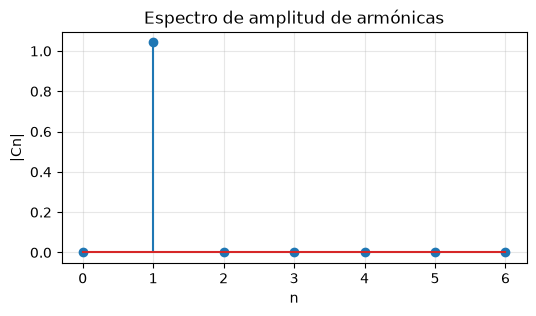


Gráfica de comprobación (usa 6 armónicas solo para visualizar):


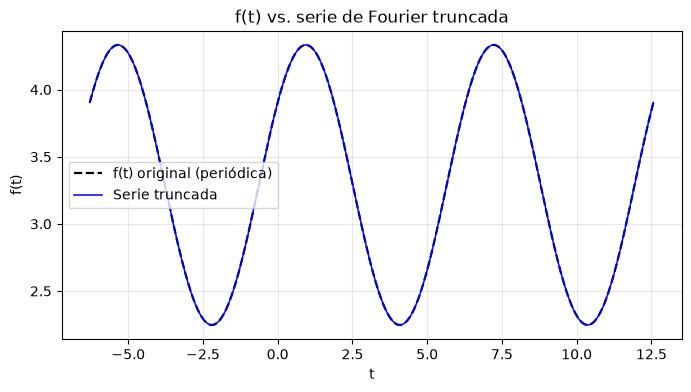

{'f': 1053*sin(t)/1250 + 614159*cos(t)/1000000 + pi**2/3,
 'dc': pi**2/3,
 'an': Piecewise((0, n > 1), (614159/1000000, True)),
 'bn': Piecewise((0, n > 1), (1053/1250, True)),
 'w0': 1,
 'T': 2*pi,
 'serie_exacta': Sum(Piecewise((0, n > 1), (1053*sin(n*t)/1250 + 614159*cos(n*t)/1000000, True)), (n, 1, oo)) + pi**2/3,
 'serie_aprox_grafica': 1053*sin(t)/1250 + 614159*cos(t)/1000000 + pi**2/3,
 'tabla': [(0, 0.0, 0.0, 0.0),
  (1, 0.614159, 0.8424, 1.042510929094271),
  (2, 0.0, 0.0, 0.0),
  (3, 0.0, 0.0, 0.0),
  (4, 0.0, 0.0, 0.0),
  (5, 0.0, 0.0, 0.0),
  (6, 0.0, 0.0, 0.0)]}

In [7]:
# ✏️ EDITA SOLO AQUÍ
FUNCION = "((pi**2)/3)+0.8424sen(t)+0.614159cos(t)"
DESDE = 0
HASTA = 2*pi
N = 6
# 🛑 NO TOCAR DESDE AQUÍ
resolver_fourier_exacta(FUNCION, DESDE, HASTA, N=N)


## PANEL 2B — Fourier EXACTA de función por partes

Hace lo mismo que el **Panel 2**, pero muestra la representación infinita exacta con $\sum_{n=1}^{\infty}$.

Cada tramo sigue siendo: **(`función`, `inicio`, `fin`)**.


Función por tramos detectada:


⎧0  for t ≥ -5 ∧ t < 0
⎪                     
⎨1  for t ≥ 0 ∧ t < 5 
⎪                     
⎩0      otherwise     

SERIE TRIGONOMÉTRICA DE FOURIER — EXACTA


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>


SERIE EXACTA / FORMA GENERAL:


<IPython.core.display.Math object>


Tabla y espectro de las primeras armónicas:
  n         an         bn         Cn    % fund.
------------------------------------------------
  0     0.0000     0.0000     0.0000       0.0%
  1     0.0000     0.6366     0.6366     100.0%
  2     0.0000     0.0000     0.0000       0.0%
  3     0.0000     0.2122     0.2122      33.3%
  4     0.0000     0.0000     0.0000       0.0%
  5     0.0000     0.1273     0.1273      20.0%
  6     0.0000     0.0000     0.0000       0.0%


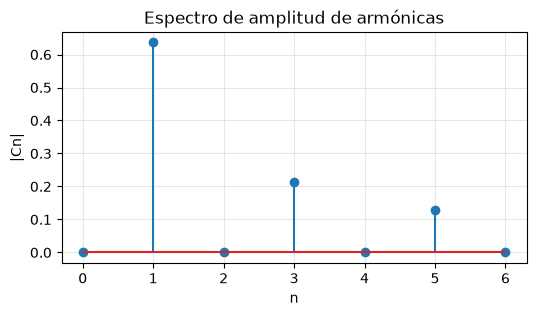


Gráfica de comprobación (usa 6 armónicas solo para visualizar):


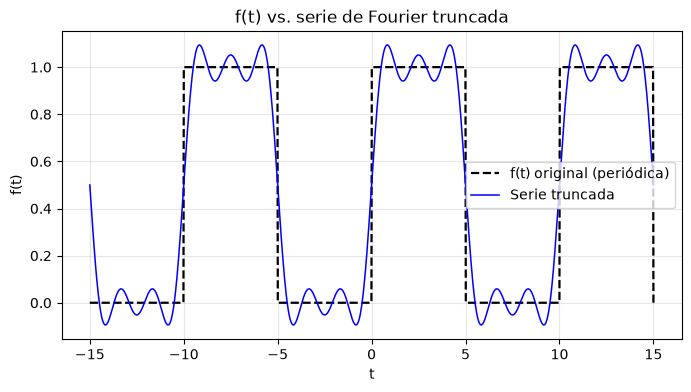

{'f': Piecewise((0, (t >= -5) & (t < 0)), (1, (t >= 0) & (t < 5)), (0, True)),
 'dc': 1/2,
 'an': 0,
 'bn': (1 - (-1)**n)/(pi*n),
 'w0': pi/5,
 'T': 10,
 'serie_exacta': Sum(-(-1)**n*sin(pi*n*t/5)/(pi*n) + sin(pi*n*t/5)/(pi*n), (n, 1, oo)) + 1/2,
 'serie_aprox_grafica': 2*sin(pi*t/5)/pi + 2*sin(3*pi*t/5)/(3*pi) + 2*sin(pi*t)/(5*pi) + 1/2,
 'tabla': [(0, 0.0, 0.0, 0.0),
  (1, 0.0, 0.6366197723675814, 0.6366197723675814),
  (2, 0.0, 0.0, 0.0),
  (3, 0.0, 0.2122065907891938, 0.2122065907891938),
  (4, 0.0, 0.0, 0.0),
  (5, 0.0, 0.12732395447351627, 0.12732395447351627),
  (6, 0.0, 0.0, 0.0)]}

In [12]:
# ✏️ EDITA SOLO AQUÍ
TRAMOS = [
    (0, -5, 0),
    (1,  0, 5),
]
DESDE = -5
HASTA = 5
N = 6
# 🛑 NO TOCAR DESDE AQUÍ
resolver_fourier_tramos_exacta(TRAMOS, desde=DESDE, hasta=HASTA, N=N)


## PANEL 3 — Serie de medio rango

Cambia solo los datos marcados y ejecuta la celda de abajo.


SERIE DE MEDIO RANGO


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>


Serie truncada:


<IPython.core.display.Math object>


Gráfica de la extensión y la serie:


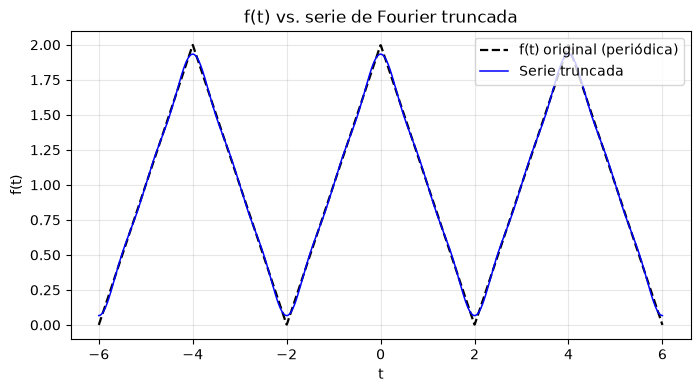

{'f': 2 - t,
 'dc': 1,
 'an': 4*(1 - (-1)**n)/(pi**2*n**2),
 'bn': 0,
 'w0': pi/2,
 'T': 4,
 'serie': 8*cos(pi*t/2)/pi**2 + 8*cos(3*pi*t/2)/(9*pi**2) + 8*cos(5*pi*t/2)/(25*pi**2) + 1}

In [9]:
# ✏️ EDITA SOLO AQUÍ
FUNCION = "2 - t"
L = 2
TIPO = "coseno"      # "seno" o "coseno"
N = 6
# 🛑 NO TOCAR DESDE AQUÍ
resolver_medio_rango(FUNCION, L=L, tipo=TIPO, N=N)


## PANEL 4 — Senoides/cosenos: amplitud, f, ω, T, fase y armónicas

Cambia solo los datos marcados y ejecuta la celda de abajo.

**T1 = primer término escrito, T2 = segundo, T3 = tercero, etc.**  
La tabla también imprime la expresión original de cada término para que nunca haya duda.


ANÁLISIS AUTOMÁTICO DE SENOIDES / COSENOS
Función ingresada:


<IPython.core.display.Math object>


IMPORTANTE: T1, T2, T3... siguen el orden en que escribiste los términos.

Correspondencia:
  T1  ->  3 · cos(50t)
  T2  ->  + 3 · cos(100t+(1/10))
  T3  ->  + 1 · cos(150t+(1/8))

Resultados:
 Term    tipo        Amp              f                w              T         fase    arm.
----------------------------------------------------------------------------------------------
   T1     cos          3          25/pi               50          pi/25            0       1
   T2     cos          3          50/pi              100          pi/50         1/10       2
   T3     cos          1          75/pi              150          pi/75          1/8       3

Qué significa cada fila:
  T1 = 3 · cos(50t)
  T2 = + 3 · cos(100t+(1/10))
  T3 = + 1 · cos(150t+(1/8))

Frecuencia fundamental:


<IPython.core.display.Math object>

Período fundamental:


<IPython.core.display.Math object>

Frecuencia angular fundamental:


<IPython.core.display.Math object>

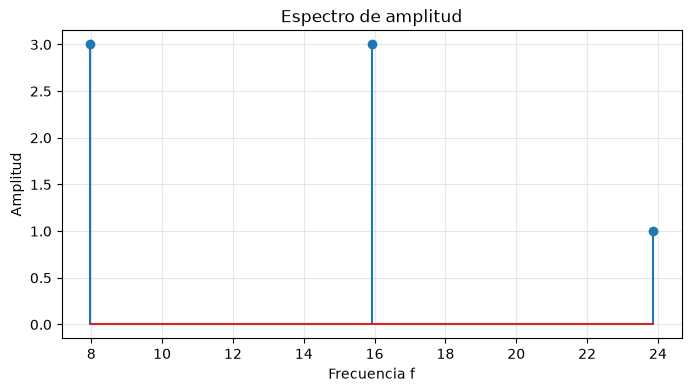


Gráfica de la señal total y sus componentes:


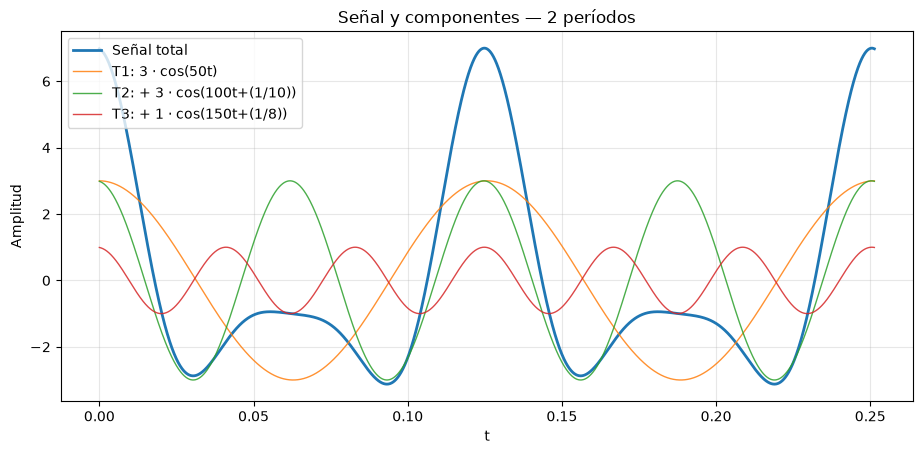

{'f': 3*cos(50*t) + 3*cos(100*t + 1/10) + cos(150*t + 1/8),
 'filas': [{'numero': 1,
   'nombre': 'T1',
   'expresion': '3 · cos(50t)',
   'A_original': 3,
   'A': 3,
   'f': 25/pi,
   'w': 50,
   'T': pi/25,
   'phi_original': 0,
   'phi': 0,
   'tipo': 'cos',
   'armonica': 1},
  {'numero': 2,
   'nombre': 'T2',
   'expresion': '+ 3 · cos(100t+(1/10))',
   'A_original': 3,
   'A': 3,
   'f': 50/pi,
   'w': 100,
   'T': pi/50,
   'phi_original': 1/10,
   'phi': 1/10,
   'tipo': 'cos',
   'armonica': 2},
  {'numero': 3,
   'nombre': 'T3',
   'expresion': '+ 1 · cos(150t+(1/8))',
   'A_original': 1,
   'A': 1,
   'f': 75/pi,
   'w': 150,
   'T': pi/75,
   'phi_original': 1/8,
   'phi': 1/8,
   'tipo': 'cos',
   'armonica': 3}],
 'T': pi/25,
 'terminos': [{'A': 3,
   'w': 50,
   'phi': 0,
   'tipo': 'cos',
   'expresion': '3 · cos(50t)'},
  {'A': 3,
   'w': 100,
   'phi': 1/10,
   'tipo': 'cos',
   'expresion': '+ 3 · cos(100t+(1/10))'},
  {'A': 1,
   'w': 150,
   'phi': 1/8,
   'tipo': 

In [6]:
# ✏️ EDITA SOLO AQUÍ π·
FUNCION = "3 · cos(50t) + 3 · cos(100t+(1/10)) + 1 · cos(150t+(1/8))"
PERIODOS_A_GRAFICAR = 2
# 🛑 NO TOCAR DESDE AQUÍ
resolver_senoides(FUNCION, periodos=PERIODOS_A_GRAFICAR)


## PANEL 5 — Serie compleja / exponencial

Cambia solo los datos marcados y ejecuta la celda de abajo.


SERIE COMPLEJA DE FOURIER


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>


   n       |cn|   fase (rad)
------------------------------
 -10     0.3658      -1.4711
  -9     0.4060       1.6815
  -8     0.4560      -1.4464
  -7     0.5199       1.7127
  -6     0.6043      -1.4056
  -5     0.7209       1.7682
  -4     0.8916      -1.3258
  -3     1.1625       1.8925
  -2     1.6440      -1.1071
  -1     2.5994       2.3562
   0     3.6761       0.0000
   1     2.5994      -2.3562
   2     1.6440       1.1071
   3     1.1625      -1.8925
   4     0.8916       1.3258
   5     0.7209      -1.7682
   6     0.6043       1.4056
   7     0.5199      -1.7127
   8     0.4560       1.4464
   9     0.4060      -1.6815
  10     0.3658       1.4711


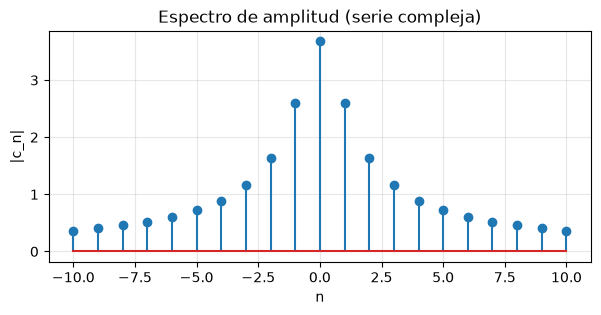

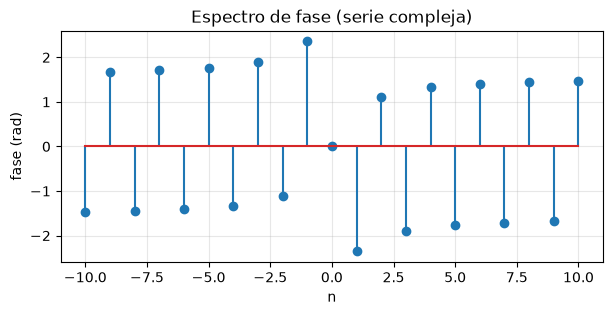



In [6]:
# ✏️ EDITA SOLO AQUÍ
FUNCION = "e^t"
DESDE = -pi
HASTA = pi
N = 10
# 🛑 NO TOCAR DESDE AQUÍ
resolver_compleja(FUNCION, DESDE, HASTA, N=N)


## PANEL 6 — Serie compleja por tramos

Cambia solo los datos marcados y ejecuta la celda de abajo.


In [ ]:
# ✏️ EDITA SOLO AQUÍ
TRAMOS = [
    (1, 0, 2),
    (0, 2, 4),
]
DESDE = 0
HASTA = 4
N = 10
# 🛑 NO TOCAR DESDE AQUÍ
resolver_compleja_tramos(TRAMOS, desde=DESDE, hasta=HASTA, N=N)


## PANEL 7 — Serie ya dada: truncar, período y armónicas

Cambia solo los datos marcados y ejecuta la celda de abajo.


SERIE DADA — TRUNCAMIENTO Y ARMÓNICAS


<IPython.core.display.Math object>

<IPython.core.display.Math object>

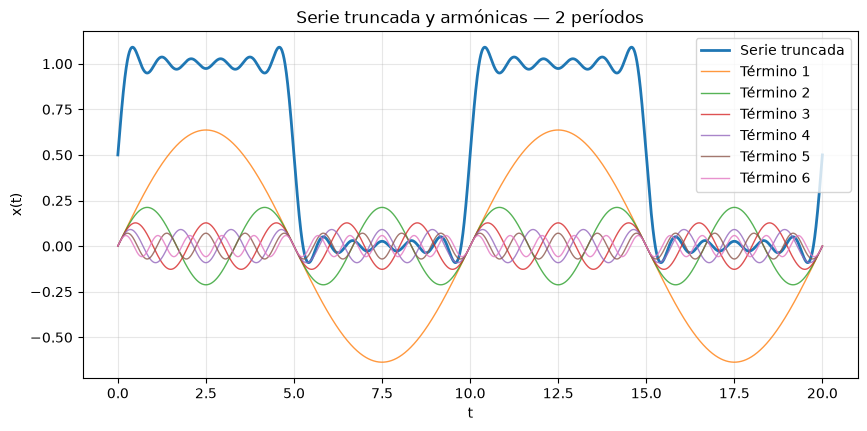

{'serie': (13860*sin(pi*t/5) + 4620*sin(3*pi*t/5) + 2772*sin(pi*t) + 1980*sin(7*pi*t/5) + 1540*sin(9*pi*t/5) + 1260*sin(11*pi*t/5) + 3465*pi)/(6930*pi),
 'indices': [1, 3, 5, 7, 9, 11],
 'componentes': [2*sin(pi*t/5)/pi,
  2*sin(3*pi*t/5)/(3*pi),
  2*sin(pi*t)/(5*pi),
  2*sin(7*pi*t/5)/(7*pi),
  2*sin(9*pi*t/5)/(9*pi),
  2*sin(11*pi*t/5)/(11*pi)],
 'T': 10}

In [ ]:
# ✏️ EDITA SOLO AQUÍ
DC = "1/2"
COEF = "2/(pi*n)"
W0 = "pi / 5"
TIPO = "sin"
PATRON = "impares"   # "todos", "impares" o lista [1,3,6,10]
N = 6
PERIODOS_A_GRAFICAR = 2
# 🛑 NO TOCAR DESDE AQUÍ
resolver_serie_dada(dc=DC, coef=COEF, w0=W0, N=N, tipo=TIPO,
                    patron=PATRON, periodos=PERIODOS_A_GRAFICAR)


## PANEL 8 — Convertir A cos(ωt)+B sin(ωt) a una sola senoide

Cambia solo los datos marcados y ejecuta la celda de abajo.


In [ ]:
# ✏️ EDITA SOLO AQUÍ
A_COS = 3
B_SIN = 0
W = 3
# 🛑 NO TOCAR DESDE AQUÍ
resolver_combinar(Acos=A_COS, Bsin=B_SIN, w=W)


RESPUESTA EN FORMA SENO


## PANEL 9 — Graficar función periódica

Cambia solo los datos marcados y ejecuta la celda de abajo.


Función:


<IPython.core.display.Math object>

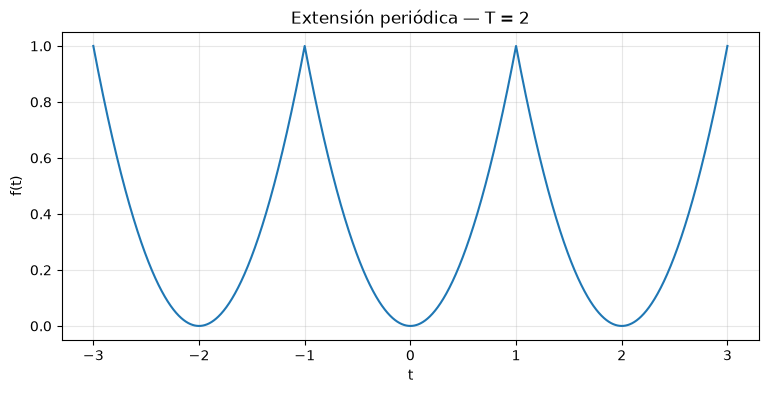

<IPython.core.display.Math object>

In [ ]:
# ✏️ EDITA SOLO AQUÍ
FUNCION = "t^2"
DESDE = -1
HASTA = 1
PERIODOS_A_GRAFICAR = 3
# 🛑 NO TOCAR DESDE AQUÍ
resolver_periodica(FUNCION, DESDE, HASTA, periodos=PERIODOS_A_GRAFICAR)


## PANEL 10 — Graficar función periódica por tramos

Cambia solo los datos marcados y ejecuta la celda de abajo.


⎧-t  for t ≥ -2 ∧ t < 0
⎪                      
⎨t   for t ≥ 0 ∧ t < 1 
⎪                      
⎩0       otherwise     

Función:


<IPython.core.display.Math object>

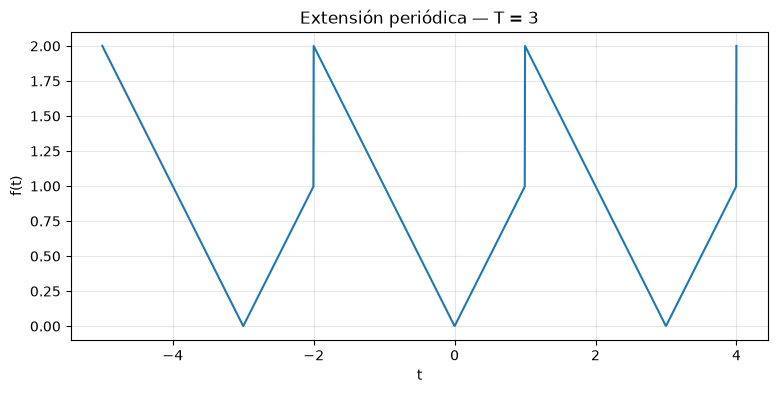

<IPython.core.display.Math object>

In [ ]:
# ✏️ EDITA SOLO AQUÍ
TRAMOS = [
    ("-t", -2, 0),
    ("t",   0, 1),
]
DESDE = -2
HASTA = 1
PERIODOS_A_GRAFICAR = 3
# 🛑 NO TOCAR DESDE AQUÍ
resolver_periodica_tramos(TRAMOS, desde=DESDE, hasta=HASTA,
                          periodos=PERIODOS_A_GRAFICAR)


## PANEL 11 — Paridad / simetría

Cambia solo los datos marcados y ejecuta la celda de abajo.


In [ ]:
# ✏️ EDITA SOLO AQUÍ
FUNCION = "t^3*sin(t)"
T = None             # si te dieron período, ejemplo: T = 2*pi
# 🛑 NO TOCAR DESDE AQUÍ
resolver_paridad(FUNCION, T=T)


## PANEL 12 — Integral por simetría

Cambia solo los datos marcados y ejecuta la celda de abajo.


In [ ]:
# ✏️ EDITA SOLO AQUÍ
INTEGRANDO = "t^3*sin(t)"
L = pi               # límites serán -L a +L
# 🛑 NO TOCAR DESDE AQUÍ
resolver_integral_simetria(INTEGRANDO, L=L)


## PANEL 13 — Ortogonalidad

Cambia solo los datos marcados y ejecuta la celda de abajo.


In [ ]:
# ✏️ EDITA SOLO AQUÍ
M = 2
N_ARM = 3
W = 1
TIPO_1 = "cos"
TIPO_2 = "cos"
LIMITES = None       # ejemplo: (-pi, pi)
# 🛑 NO TOCAR DESDE AQUÍ
resolver_ortogonalidad(M, N_ARM, w=W, tipo1=TIPO_1, tipo2=TIPO_2,
                       limites=LIMITES)


## PANEL 14 — Reconstruir desde espectro amplitud/fase

Cambia solo los datos marcados y ejecuta la celda de abajo.


In [ ]:
# ✏️ EDITA SOLO AQUÍ
DC = 5
COMPONENTES = [
    (3/2, 50,  pi/8),   # (amplitud, frecuencia_Hz, fase)
    (6,   300, pi/2),
]
PERIODOS_A_GRAFICAR = 2
# 🛑 NO TOCAR DESDE AQUÍ
resolver_desde_espectro(dc=DC, componentes=COMPONENTES,
                        periodos=PERIODOS_A_GRAFICAR)


## PANEL 15 — Pulso PWM

Cambia solo los datos marcados y ejecuta la celda de abajo.


In [ ]:
# ✏️ EDITA SOLO AQUÍ
A = 1
M = 2
T = 5
N = 6
# 🛑 NO TOCAR DESDE AQUÍ
resolver_pwm(A=A, m=M, T=T, N=N)


## PANEL 16 — Diodo: Taylor + Fourier

Cambia solo los datos marcados y ejecuta la celda de abajo.


In [ ]:
# ✏️ EDITA SOLO AQUÍ
A = 0.1
K = 6
VM = 0.2
W = 1
ORDEN_TAYLOR = 4
# 🛑 NO TOCAR DESDE AQUÍ
resolver_diodo(a=A, k=K, Vm=VM, w=W, orden=ORDEN_TAYLOR)


# ✅ REGLA FINAL

- No escribas llamadas en otra celda.
- No reutilices variables de otro ejercicio.
- Cambia los inputs en el panel.
- Ejecuta esa misma celda.
- Si reinicias el kernel, vuelve a ejecutar solo **CARGAR HERRAMIENTA**.
